# TP2 KASDAD - Klasifikasi `artifact_signal`

**EDA individual:** Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?

Routing (C4_HGB) memakai hybrid structured + TF-IDF Logistic Regression saat teks terisi, dan structured HGB saat kosong. Metrik utama: **Macro F1**.

Kelompok **A06 - KasdudLovers** | **Samuel Indriano** | NPM **2406400524**.

Notebook mencakup data, EDA, preprocessing, pemodelan, dan evaluasi temporal. Approach individual ini berbeda dari ensemble champion kelompok terbaru.

## 1. Persiapan dan data

Sediakan official `classification/Train.csv` di bawah `TP2_DATA_DIR` (default: `data/raw/` di current directory atau parent). `TP2_DATA_DIR` menunjuk folder yang berisi `classification/` dan `regression/`. Notebook ini memuat seluruh helper EDA, preprocessing, model, dan metrik custom di dalam cell; ia tidak mengimpor file project lokal. Test inference tetap nonaktif.

Dependensi Python: NumPy, pandas, SciPy, scikit-learn, Matplotlib, threadpoolctl, IPython/Jupyter.

In [1]:
from __future__ import annotations
from pathlib import Path
import hashlib
import json
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

def find_data_root():
    configured = os.environ.get("TP2_DATA_DIR")
    if configured:
        root = Path(configured).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(f"TP2_DATA_DIR is not a directory: {root}")
        return root
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        for root in (candidate / "data" / "raw", candidate / "raw", candidate):
            if any((root / task).is_dir() for task in ("classification", "regression")):
                return root
    return current / "data" / "raw"

DATA_ROOT = find_data_root()

def task_files(task, root=None):
    if task not in {"classification", "regression"}:
        raise ValueError(f"Unknown task: {task}")
    folder = (Path(root) if root is not None else DATA_ROOT) / task
    files = {}
    for role, stem in (("train", "train"), ("test", "test"), ("sample", "samplesubmission")):
        matches = [p for p in folder.iterdir() if p.is_file() and p.suffix.lower() == ".csv" and p.stem.lower() == stem] if folder.is_dir() else []
        if len(matches) > 1:
            raise ValueError(f"Ambiguous {task}/{role}: {[p.name for p in matches]}")
        files[role] = matches[0] if matches else None
    return files

# Historical official input identity, copied from the verified experiment freeze.
EXPECTED_CLASSIFICATION_TRAIN_SHA256 = "875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526e2f0a76747942ed91c"
CLASSIFICATION_FEATURE_SETS = {'two': ['impact_load', 'entry_friction'],
 'ef': ['entry_friction'],
 'structured': ['impact_load',
                'entry_friction',
                'cycle_code',
                'scope_pressure',
                'text_load',
                'scope_trace',
                'org_spread',
                'module_spread',
                'telemetry_flag',
                'org_code',
                'module_code',
                'pattern_code'],
 'text': ['signal_stream'],
 'hybrid': ['impact_load',
            'entry_friction',
            'cycle_code',
            'scope_pressure',
            'text_load',
            'scope_trace',
            'org_spread',
            'module_spread',
            'telemetry_flag',
            'org_code',
            'module_code',
            'pattern_code',
            'signal_stream']}

get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
print("Data root:", DATA_ROOT)
print("Override with TP2_DATA_DIR pointing to the folder that contains classification/ and regression/.")

Data root: C:\Users\Sam\AppData\Local\Temp\samuel_root_standalone_b67fvf1w\data\raw
Override with TP2_DATA_DIR pointing to the folder that contains classification/ and regression/.


### Preprocessing dan definisi model

Fungsi berikut menangani format numerik, nilai kosong, kategori, representasi teks, dan model. Semua parameter preprocessing dipelajari dari data training pada fold yang bersangkutan. Kode tersedia langsung di sel dan dapat dibuka untuk diperiksa.

In [2]:
# Inline implementation from src/models/round1_models.py; source SHA-256 766e0c2e183c5aa653a5c5b81aae4d646e99cecdcd043bead3eadb99edd0a7a4.
"""Leakage-safe estimator wrappers for TP2 Regression Round 1.

The module deliberately implements only the preregistered baseline and model
families. It does not load data, split rows, train a full model, or write model
artifacts; the experiment runner owns those choices.
"""


import hashlib
import json
import math
import numbers
import re
from collections import Counter, defaultdict
from typing import Any

import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OrdinalEncoder, StandardScaler


TWO_FEATURES = ("impact_load", "entry_friction")
EXPANDED_FEATURES = (
    "impact_load",
    "entry_friction",
    "cycle_code",
    "scope_pressure",
    "text_load",
    "scope_trace",
    "org_spread",
    "module_spread",
    "telemetry_flag",
    "org_code",
    "module_code",
    "pattern_code",
)
NUMERIC_FEATURES = (
    "impact_load",
    "entry_friction",
    "cycle_code",
    "scope_pressure",
    "text_load",
)
MIXED_COUNT_FEATURES = ("scope_trace", "org_spread", "module_spread")
CATEGORICAL_FEATURES = ("org_code", "module_code", "pattern_code")
TELEMETRY_FEATURE = "telemetry_flag"
_KIND_NAMES = {"global_median", "impact_median", "joint_median", "linear", "hgb"}
_COUNT_TOKEN = re.compile(
    r"^\s*(?P<approx>~)?\s*(?P<number>\d+(?:\.\d+)?)\s*(?P<unit>.*?)\s*$"
)
_TELEMETRY_MAP = {
    "inactive": 0.0,
    "false": 0.0,
    "n": 0.0,
    "0": 0.0,
    "active": 1.0,
    "true": 1.0,
    "y": 1.0,
    "1": 1.0,
}
_FIXED_HGB_PARAMS: dict[str, Any] = {
    "learning_rate": 0.05,
    "max_iter": 200,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 30,
    "l2_regularization": 1.0,
    "max_bins": 255,
    "early_stopping": False,
    "random_state": 42,
}


def _is_missing(value: Any) -> bool:
    try:
        return bool(pd.isna(value))
    except (TypeError, ValueError):
        return False


def _number_array(series: pd.Series) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return numeric values, missing flags, and invalid-format flags."""
    missing = series.map(_is_missing).to_numpy(dtype=bool)
    text_blank = series.map(lambda value: isinstance(value, str) and not value.strip()).to_numpy(dtype=bool)
    missing |= text_blank
    numeric = pd.to_numeric(series.mask(missing), errors="coerce").to_numpy(dtype=float)
    finite = np.isfinite(numeric)
    invalid = (~missing) & (~finite)
    numeric[~finite] = np.nan
    return numeric, missing.astype(float), invalid.astype(float)


def _mixed_count_arrays(
    series: pd.Series,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Parse counts without guessing; only numbers and an optional ``nodes`` unit are accepted."""
    n = len(series)
    value = np.full(n, np.nan, dtype=float)
    approximate = np.zeros(n, dtype=float)
    suffix_present = np.zeros(n, dtype=float)
    parse_fail = np.zeros(n, dtype=float)
    missing = np.zeros(n, dtype=float)
    for position, raw in enumerate(series.to_numpy(dtype=object)):
        if _is_missing(raw) or (isinstance(raw, str) and not raw.strip()):
            missing[position] = 1.0
            continue
        match = _COUNT_TOKEN.fullmatch(str(raw))
        if match is None:
            parse_fail[position] = 1.0
            continue
        unit = match.group("unit").strip().casefold()
        suffix_present[position] = float(bool(unit))
        if unit not in {"", "nodes"}:
            parse_fail[position] = 1.0
            continue
        parsed = float(match.group("number"))
        if not math.isfinite(parsed):
            parse_fail[position] = 1.0
            continue
        value[position] = parsed
        approximate[position] = float(match.group("approx") is not None)
    return value, approximate, suffix_present, parse_fail, missing


def _telemetry_arrays(series: pd.Series) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Map the observed binary spellings and retain unknown/missing flags."""
    n = len(series)
    value = np.full(n, np.nan, dtype=float)
    unknown = np.zeros(n, dtype=float)
    missing = np.zeros(n, dtype=float)
    for position, raw in enumerate(series.to_numpy(dtype=object)):
        if _is_missing(raw) or (isinstance(raw, str) and not raw.strip()):
            missing[position] = 1.0
            continue
        normalized = str(raw).strip().casefold()
        if normalized not in _TELEMETRY_MAP:
            unknown[position] = 1.0
            continue
        value[position] = _TELEMETRY_MAP[normalized]
    return value, unknown, missing


def _category_array(series: pd.Series) -> np.ndarray:
    normalized = np.empty(len(series), dtype=object)
    for position, raw in enumerate(series.to_numpy(dtype=object)):
        if _is_missing(raw) or (isinstance(raw, str) and not raw.strip()):
            normalized[position] = np.nan
        else:
            normalized[position] = str(raw).strip()
    return normalized


def _to_builtin(value: Any) -> Any:
    """Convert audit metadata to JSON-safe Python scalars and containers."""
    if isinstance(value, dict):
        return {str(key): _to_builtin(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [_to_builtin(item) for item in value]
    if isinstance(value, np.ndarray):
        return [_to_builtin(item) for item in value.tolist()]
    if isinstance(value, np.generic):
        return _to_builtin(value.item())
    if isinstance(value, float) and not math.isfinite(value):
        return None
    if isinstance(value, (str, int, float, bool)) or value is None:
        return value
    return str(value)


def _fingerprint_value(value: Any) -> str:
    if _is_missing(value):
        return "null"
    if isinstance(value, (bool, np.bool_)):
        return "bool:" + ("1" if value else "0")
    if isinstance(value, numbers.Integral):
        return f"int:{int(value)}"
    if isinstance(value, numbers.Real):
        value_float = float(value)
        if not math.isfinite(value_float):
            return "float:" + repr(value_float)
        return "float:" + value_float.hex()
    return "str:" + str(value)


def _fit_fingerprint(X: pd.DataFrame, feature_names: tuple[str, ...], y: np.ndarray) -> str:
    """Hash the exact selected training inputs and target without retaining rows."""
    digest = hashlib.sha256()

    def add_text(text: str) -> None:
        encoded = text.encode("utf-8", errors="surrogatepass")
        digest.update(len(encoded).to_bytes(8, "big"))
        digest.update(encoded)

    add_text(json.dumps(feature_names, ensure_ascii=False, separators=(",", ":")))
    add_text(str(len(X)))
    for column in feature_names:
        for value in X[column].to_numpy(dtype=object):
            add_text(_fingerprint_value(value))
    for value in y:
        add_text(_fingerprint_value(float(value)))
    return digest.hexdigest()


def _validate_dataframe(X: pd.DataFrame) -> None:
    if not isinstance(X, pd.DataFrame):
        raise TypeError("X must be a pandas DataFrame so feature names can be audited")
    if X.columns.has_duplicates:
        raise ValueError("X has duplicate column names")


def _target_array(y: Any, expected_rows: int) -> np.ndarray:
    target = np.asarray(y)
    if target.ndim != 1:
        raise ValueError("y must be one-dimensional")
    if len(target) != expected_rows:
        raise ValueError("X and y row counts differ")
    try:
        target = target.astype(float)
    except (TypeError, ValueError) as exc:
        raise ValueError("y must contain numeric regression targets") from exc
    if not np.isfinite(target).all():
        raise ValueError("y must be finite and non-missing")
    if expected_rows == 0:
        raise ValueError("Cannot fit on an empty training set")
    return target


class _HGBPreprocessor:
    """Training-fold-fitted numeric imputation and native categorical encoding."""

    def __init__(self, feature_preset: str):
        self.feature_preset = feature_preset
        self.encoder: OrdinalEncoder | None = None
        self.medians: dict[str, float] = {}
        self.transformed_feature_names: list[str] = []
        self.numeric_feature_names: list[str] = []
        self.categorical_positions: list[int] = []
        self.category_counts: dict[str, dict[str, Any]] = {}
        self.seen_categories: dict[str, set[str]] = {}

    def _raw_matrix(
        self, X: pd.DataFrame, *, fit_categories: bool
    ) -> tuple[np.ndarray, list[str], list[str], list[str], dict[str, np.ndarray], dict[str, np.ndarray]]:
        if self.feature_preset == "two":
            columns: list[np.ndarray] = []
            names: list[str] = []
            for feature in TWO_FEATURES:
                values, missing, invalid = _number_array(X[feature])
                if np.any(missing) or np.any(invalid):
                    raise ValueError(f"two-feature HGB requires complete numeric {feature!r} values")
                columns.append(values)
                names.append(feature)
            return np.column_stack(columns), names, names.copy(), [], {}, {}

        numeric_columns: list[np.ndarray] = []
        numeric_names: list[str] = []
        categorical_columns: list[np.ndarray] = []
        categorical_names: list[str] = []
        category_raw: dict[str, np.ndarray] = {}
        category_missing: dict[str, np.ndarray] = {}
        for feature in EXPANDED_FEATURES:
            if feature in NUMERIC_FEATURES:
                values, missing, invalid = _number_array(X[feature])
                numeric_columns.extend((values, invalid, missing))
                numeric_names.extend((feature, f"{feature}__parsefail", f"{feature}__missing"))
            elif feature in MIXED_COUNT_FEATURES:
                values, approximate, suffix_present, invalid, missing = _mixed_count_arrays(X[feature])
                numeric_columns.extend((values, approximate, suffix_present, invalid, missing))
                numeric_names.extend(
                    (
                        feature,
                        f"{feature}__approximate",
                        f"{feature}__suffix_present",
                        f"{feature}__parsefail",
                        f"{feature}__missing",
                    )
                )
            elif feature == TELEMETRY_FEATURE:
                values, unknown, missing = _telemetry_arrays(X[feature])
                numeric_columns.extend((values, unknown, missing))
                numeric_names.extend(
                    (feature, f"{feature}__unknown", f"{feature}__missing")
                )
            elif feature in CATEGORICAL_FEATURES:
                raw = _category_array(X[feature])
                category_raw[feature] = raw
                category_missing[feature] = np.array(
                    [value is np.nan or _is_missing(value) for value in raw], dtype=float
                )
                categorical_columns.append(raw)
                categorical_names.append(feature)

        if fit_categories:
            self.encoder = OrdinalEncoder(
                min_frequency=30,
                max_categories=254,
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-1,
                dtype=np.float64,
            )
            category_matrix = np.column_stack(categorical_columns)
            self.encoder.fit(category_matrix)
            for index, feature in enumerate(categorical_names):
                categories = self.encoder.categories_[index]
                seen = {
                    str(value)
                    for value in categories
                    if not _is_missing(value)
                }
                self.seen_categories[feature] = seen

        if categorical_columns:
            if self.encoder is None:
                raise RuntimeError("Categorical encoder was not fitted")
            encoded = self.encoder.transform(np.column_stack(categorical_columns))
        else:
            encoded = np.empty((len(X), 0), dtype=float)

        matrix_columns: list[np.ndarray] = []
        all_names: list[str] = []
        numeric_output_names: list[str] = []
        categorical_positions: list[int] = []
        numeric_index = 0
        categorical_index = 0
        for feature in EXPANDED_FEATURES:
            if feature in NUMERIC_FEATURES:
                for _ in range(3):
                    matrix_columns.append(numeric_columns[numeric_index])
                    all_names.append(numeric_names[numeric_index])
                    numeric_output_names.append(numeric_names[numeric_index])
                    numeric_index += 1
            elif feature in MIXED_COUNT_FEATURES:
                for _ in range(5):
                    matrix_columns.append(numeric_columns[numeric_index])
                    all_names.append(numeric_names[numeric_index])
                    numeric_output_names.append(numeric_names[numeric_index])
                    numeric_index += 1
            elif feature == TELEMETRY_FEATURE:
                for _ in range(3):
                    matrix_columns.append(numeric_columns[numeric_index])
                    all_names.append(numeric_names[numeric_index])
                    numeric_output_names.append(numeric_names[numeric_index])
                    numeric_index += 1
            elif feature in CATEGORICAL_FEATURES:
                categorical_positions.append(len(all_names))
                matrix_columns.append(encoded[:, categorical_index])
                all_names.append(f"{feature}__ordinal")
                categorical_index += 1
                matrix_columns.append(category_missing[feature])
                all_names.append(f"{feature}__missing")
                numeric_output_names.append(f"{feature}__missing")

        matrix = np.column_stack(matrix_columns).astype(float, copy=False)
        if fit_categories:
            for index, feature in enumerate(categorical_names):
                raw = category_raw[feature]
                observed = [str(value) for value in raw if not _is_missing(value)]
                freq = Counter(observed)
                encoded_train = encoded[:, index]
                represented = np.unique(encoded_train[encoded_train >= 0])
                infrequent = getattr(self.encoder, "infrequent_categories_", None)
                infrequent_count = 0
                if infrequent is not None and infrequent[index] is not None:
                    infrequent_count = len(infrequent[index])
                self.category_counts[feature] = {
                    "observed_unique": len(freq),
                    "encoded_categories": int(len(represented)),
                    "infrequent_categories": int(infrequent_count),
                    "training_missing_rows": int(sum(_is_missing(value) for value in raw)),
                    "training_rows": len(raw),
                    "min_frequency": 30,
                    "max_categories": 254,
                }
        return matrix, all_names, numeric_output_names, categorical_names, category_raw, category_missing

    def fit_transform(self, X: pd.DataFrame) -> tuple[np.ndarray, list[bool]]:
        matrix, names, numeric_names, _, _, _ = self._raw_matrix(X, fit_categories=True)
        self.transformed_feature_names = names
        self.numeric_feature_names = numeric_names
        categorical_name_set = {f"{name}__ordinal" for name in CATEGORICAL_FEATURES}
        self.categorical_positions = [
            position for position, name in enumerate(names) if name in categorical_name_set
        ]
        numeric_positions = [
            position for position, name in enumerate(names) if name not in categorical_name_set
        ]
        self.medians = {}
        for position in numeric_positions:
            column = matrix[:, position]
            finite = column[np.isfinite(column)]
            median = float(np.median(finite)) if len(finite) else 0.0
            self.medians[names[position]] = median
            column[~np.isfinite(column)] = median
        categorical_mask = [position in self.categorical_positions for position in range(len(names))]
        return matrix, categorical_mask

    def transform(self, X: pd.DataFrame) -> tuple[np.ndarray, dict[str, int]]:
        matrix, names, _, categorical_names, category_raw, _ = self._raw_matrix(
            X, fit_categories=False
        )
        if names != self.transformed_feature_names:
            raise RuntimeError("Transformed feature schema changed after fit")
        unknown_counts: dict[str, int] = {}
        for feature in categorical_names:
            raw = category_raw[feature]
            seen = self.seen_categories[feature]
            unknown_counts[feature] = int(
                sum(not _is_missing(value) and str(value) not in seen for value in raw)
            )
        categorical_set = set(self.categorical_positions)
        for position, name in enumerate(names):
            if position in categorical_set:
                continue
            column = matrix[:, position]
            column[~np.isfinite(column)] = self.medians[name]
        return matrix, unknown_counts

    def audit_state(self) -> dict[str, Any]:
        return {
            "transformed_feature_names": list(self.transformed_feature_names),
            "numeric_imputer_medians": dict(self.medians),
            "categorical_feature_names": [
                self.transformed_feature_names[position]
                for position in self.categorical_positions
            ],
            "category_counts": dict(self.category_counts),
            "ordinal_encoder": {
                "min_frequency": 30,
                "max_categories": 254,
                "handle_unknown": "use_encoded_value",
                "unknown_value": -1,
                "encoded_missing_value": -1,
                "dtype": "float64",
            },
        }


class Round1Model:
    """Small estimator-compatible wrapper with reproducible audit metadata."""

    def __init__(self, recipe: dict[str, Any]):
        if not isinstance(recipe, dict):
            raise TypeError("recipe must be a dictionary")
        unknown_keys = set(recipe) - {"id", "kind", "features", "min_support", "params"}
        if unknown_keys:
            raise ValueError(f"Unsupported recipe fields: {sorted(unknown_keys)}")
        self.model_id = str(recipe.get("id", "round1"))
        self.kind = recipe.get("kind")
        if self.kind not in _KIND_NAMES:
            raise ValueError(f"kind must be one of {sorted(_KIND_NAMES)}")
        self.feature_preset = recipe.get("features", "two")
        if self.feature_preset not in {"two", "expanded"}:
            raise ValueError("features must be 'two' or 'expanded'")
        if self.kind == "linear" and self.feature_preset != "two":
            raise ValueError("linear is restricted to the two numeric features")
        self.min_support = recipe.get("min_support", 30)
        if not isinstance(self.min_support, numbers.Integral) or int(self.min_support) != 30:
            raise ValueError("Round 1 lookup baselines use the frozen support threshold 30")
        self.min_support = int(self.min_support)
        params = recipe.get("params", {})
        if not isinstance(params, dict):
            raise TypeError("params must be a dictionary")
        self.hgb_params: dict[str, Any] = {}
        if self.kind == "hgb":
            allowed = set(_FIXED_HGB_PARAMS) | {"loss", "interaction_cst"}
            unsupported = set(params) - allowed
            if unsupported:
                raise ValueError(f"Unsupported HGB parameters: {sorted(unsupported)}")
            loss = params.get("loss", "squared_error")
            if loss not in {"squared_error", "absolute_error"}:
                raise ValueError("HGB loss must be squared_error or absolute_error")
            for name, fixed_value in _FIXED_HGB_PARAMS.items():
                if name in params and params[name] != fixed_value:
                    raise ValueError(f"HGB {name} is frozen at {fixed_value!r}")
            interaction = params.get("interaction_cst", None)
            if interaction not in {None, "no_interactions"}:
                raise ValueError("interaction_cst may only be None or 'no_interactions'")
            self.hgb_params = {**_FIXED_HGB_PARAMS, "loss": loss}
            if interaction is not None:
                self.hgb_params["interaction_cst"] = interaction
        elif params:
            raise ValueError("Only HGB recipes accept model parameters")
        self._fitted = False
        self._state: dict[str, Any] = {}
        self._prediction_diagnostics: dict[str, Any] = {}

    def _required_feature_names(self) -> tuple[str, ...]:
        if self.kind == "global_median":
            return ()
        if self.kind == "impact_median":
            return ("impact_load",)
        if self.kind == "joint_median":
            return TWO_FEATURES
        return TWO_FEATURES if self.feature_preset == "two" else EXPANDED_FEATURES

    def _selected(self, X: pd.DataFrame) -> pd.DataFrame:
        _validate_dataframe(X)
        names = self._required_feature_names()
        missing = [name for name in names if name not in X.columns]
        if missing:
            raise ValueError(f"X is missing required feature columns: {missing}")
        return X.loc[:, list(names)]

    @staticmethod
    def _group_component(value: Any) -> float | None:
        if _is_missing(value):
            return None
        try:
            parsed = float(value)
        except (TypeError, ValueError):
            return None
        return parsed if math.isfinite(parsed) else None

    def _fit_lookup(self, X: pd.DataFrame, y: np.ndarray) -> None:
        self._global_median = float(np.median(y))
        self._group_medians: dict[tuple[float, ...], float] = {}
        self._group_counts: dict[tuple[float, ...], int] = {}
        self._impact_medians: dict[tuple[float, ...], float] = {}
        self._impact_counts: dict[tuple[float, ...], int] = {}
        self._entry_medians: dict[tuple[float, ...], float] = {}
        self._entry_counts: dict[tuple[float, ...], int] = {}

        def summarize(columns: tuple[str, ...]) -> tuple[dict[tuple[float, ...], float], dict[tuple[float, ...], int]]:
            values: dict[tuple[float, ...], list[float]] = defaultdict(list)
            for row, target in zip(X.loc[:, list(columns)].itertuples(index=False, name=None), y):
                key_values = tuple(self._group_component(value) for value in row)
                if any(value is None for value in key_values):
                    continue
                key = tuple(float(value) for value in key_values if value is not None)
                values[key].append(float(target))
            counts = {key: len(group_y) for key, group_y in values.items()}
            medians = {key: float(np.median(group_y)) for key, group_y in values.items()}
            return medians, counts

        if self.kind == "impact_median":
            all_medians, all_counts = summarize(("impact_load",))
            kept = {key for key, count in all_counts.items() if count >= self.min_support}
            self._group_medians = {key: value for key, value in all_medians.items() if key in kept}
            self._group_counts = {key: all_counts[key] for key in kept}
        elif self.kind == "joint_median":
            joint_medians, joint_counts = summarize(TWO_FEATURES)
            impact_medians, impact_counts = summarize(("impact_load",))
            entry_medians, entry_counts = summarize(("entry_friction",))
            self._group_medians = {
                key: value for key, value in joint_medians.items() if joint_counts[key] >= self.min_support
            }
            self._group_counts = {
                key: count for key, count in joint_counts.items() if count >= self.min_support
            }
            self._impact_medians = {
                key: value for key, value in impact_medians.items() if impact_counts[key] >= self.min_support
            }
            self._impact_counts = {
                key: count for key, count in impact_counts.items() if count >= self.min_support
            }
            self._entry_medians = {
                key: value for key, value in entry_medians.items() if entry_counts[key] >= self.min_support
            }
            self._entry_counts = {
                key: count for key, count in entry_counts.items() if count >= self.min_support
            }

    def fit(self, X: pd.DataFrame, y: Any) -> "Round1Model":
        selected = self._selected(X)
        target = _target_array(y, len(selected))
        feature_names = tuple(selected.columns)
        fingerprint = _fit_fingerprint(selected, feature_names, target)
        self._fit_rows = len(target)
        self._fit_fingerprint = fingerprint
        self._input_feature_names = list(feature_names)
        self._transformed_feature_names: list[str] = []
        self._imputer_medians: dict[str, float] = {}
        self._category_counts: dict[str, dict[str, Any]] = {}
        self._hyperparameters: dict[str, Any] = {}

        if self.kind in {"global_median", "impact_median", "joint_median"}:
            self._fit_lookup(selected, target)
            self._transformed_feature_names = list(feature_names)
            self._hyperparameters = {"kind": self.kind, "min_support": self.min_support}
        elif self.kind == "linear":
            numeric = np.column_stack(
                [_number_array(selected[name])[0] for name in TWO_FEATURES]
            )
            missing = ~np.isfinite(numeric)
            if np.any(missing):
                raise ValueError("linear requires complete numeric impact_load and entry_friction")
            self._scaler = StandardScaler()
            scaled = self._scaler.fit_transform(numeric)
            self._estimator = LinearRegression()
            self._estimator.fit(scaled, target)
            self._transformed_feature_names = list(TWO_FEATURES)
            self._hyperparameters = {
                "estimator": "LinearRegression",
                "fit_intercept": True,
                "scaler": "StandardScaler",
                "scaler_with_mean": True,
                "scaler_with_std": True,
            }
        elif self.kind == "hgb":
            self._preprocessor = _HGBPreprocessor(self.feature_preset)
            matrix, categorical_mask = self._preprocessor.fit_transform(selected)
            actual_params = dict(self.hgb_params)
            actual_params["categorical_features"] = categorical_mask if any(categorical_mask) else None
            self._estimator = HistGradientBoostingRegressor(**actual_params)
            self._estimator.fit(matrix, target)
            self._transformed_feature_names = list(self._preprocessor.transformed_feature_names)
            self._imputer_medians = dict(self._preprocessor.medians)
            self._category_counts = dict(self._preprocessor.category_counts)
            self._hyperparameters = {
                key: _to_builtin(value)
                for key, value in self._estimator.get_params(deep=False).items()
            }
        self._fitted = True
        self._prediction_diagnostics = {"n_predictions": 0}
        return self

    def _predict_lookup(self, X: pd.DataFrame) -> np.ndarray:
        predictions = np.full(len(X), self._global_median, dtype=float)
        fallback_counts: Counter[str] = Counter()
        if self.kind == "global_median":
            fallback_counts["global"] = len(X)
            self._prediction_diagnostics = {
                "n_predictions": int(len(X)),
                "fallback_counts": dict(sorted(fallback_counts.items())),
            }
            return predictions
        for position, row in enumerate(X.itertuples(index=False, name=None)):
            if self.kind == "impact_median":
                impact = self._group_component(row[0])
                key = None if impact is None else (impact,)
                if key in self._group_medians:
                    predictions[position] = self._group_medians[key]
                    fallback_counts["impact"] += 1
                else:
                    fallback_counts["global"] += 1
                continue

            impact = self._group_component(row[0])
            entry = self._group_component(row[1])
            joint_key = None if impact is None or entry is None else (impact, entry)
            impact_key = None if impact is None else (impact,)
            entry_key = None if entry is None else (entry,)
            if joint_key in self._group_medians:
                predictions[position] = self._group_medians[joint_key]
                fallback_counts["joint"] += 1
            elif impact_key in self._impact_medians:
                predictions[position] = self._impact_medians[impact_key]
                fallback_counts["impact"] += 1
            elif entry_key in self._entry_medians:
                predictions[position] = self._entry_medians[entry_key]
                fallback_counts["entry_friction"] += 1
            else:
                fallback_counts["global"] += 1
        self._prediction_diagnostics = {
            "n_predictions": int(len(X)),
            "fallback_counts": dict(sorted(fallback_counts.items())),
        }
        return predictions

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before predict")
        selected = self._selected(X)
        if self.kind in {"global_median", "impact_median", "joint_median"}:
            return self._predict_lookup(selected)
        if self.kind == "linear":
            numeric = np.column_stack(
                [_number_array(selected[name])[0] for name in TWO_FEATURES]
            )
            if not np.isfinite(numeric).all():
                raise ValueError("linear requires complete numeric impact_load and entry_friction")
            predictions = self._estimator.predict(self._scaler.transform(numeric))
            self._prediction_diagnostics = {"n_predictions": int(len(selected))}
            return np.asarray(predictions, dtype=float)
        matrix, unknown_counts = self._preprocessor.transform(selected)
        predictions = self._estimator.predict(matrix)
        self._prediction_diagnostics = {
            "n_predictions": int(len(selected)),
            "unknown_category_rows": dict(sorted(unknown_counts.items())),
        }
        return np.asarray(predictions, dtype=float)

    def prediction_diagnostics(self) -> dict[str, Any]:
        return json.loads(json.dumps(_to_builtin(self._prediction_diagnostics), sort_keys=True))

    def audit_state(self) -> dict[str, Any]:
        if not self._fitted:
            raise RuntimeError("Model must be fitted before audit_state")
        state: dict[str, Any] = {
            "id": self.model_id,
            "kind": self.kind,
            "feature_preset": self.feature_preset,
            "input_feature_names": list(self._input_feature_names),
            "transformed_feature_names": list(self._transformed_feature_names),
            "fit_rows": int(self._fit_rows),
            "fit_data_sha256": self._fit_fingerprint,
            "sklearn_version": sklearn.__version__,
            "actual_hyperparameters": self._hyperparameters,
            "prediction_diagnostics": self._prediction_diagnostics,
        }
        if self.kind in {"global_median", "impact_median", "joint_median"}:
            state["min_support"] = self.min_support
            state["global_target_median"] = self._global_median
            state["supported_group_counts"] = {
                "primary": len(self._group_counts),
                "impact": len(self._impact_counts),
                "entry_friction": len(self._entry_counts),
            }

            def entries(
                medians: dict[tuple[float, ...], float], counts: dict[tuple[float, ...], int]
            ) -> list[dict[str, Any]]:
                return [
                    {"key": list(key), "rows": int(counts[key]), "median": medians[key]}
                    for key in sorted(medians)
                ]

            state["learned_group_medians"] = {
                "primary": entries(self._group_medians, self._group_counts),
                "impact": entries(self._impact_medians, self._impact_counts),
                "entry_friction": entries(self._entry_medians, self._entry_counts),
            }
        elif self.kind == "linear":
            state["standard_scaler"] = {
                "mean": self._scaler.mean_.tolist(),
                "scale": self._scaler.scale_.tolist(),
                "variance": self._scaler.var_.tolist(),
            }
            state["linear_coefficients"] = self._estimator.coef_.tolist()
            state["linear_intercept"] = float(self._estimator.intercept_)
        elif self.kind == "hgb":
            state["numeric_imputer_medians"] = dict(self._imputer_medians)
            state["category_counts"] = dict(self._category_counts)
            state["ordinal_encoder"] = self._preprocessor.audit_state()["ordinal_encoder"]
        return json.loads(json.dumps(_to_builtin(state), sort_keys=True))


def build_model(recipe: dict[str, Any]) -> Round1Model:
    """Build an unfitted Round 1 estimator from the runner's explicit recipe."""
    return Round1Model(recipe)


__all__ = [
    "CATEGORICAL_FEATURES",
    "EXPANDED_FEATURES",
    "MIXED_COUNT_FEATURES",
    "TWO_FEATURES",
    "Round1Model",
    "build_model",
]


In [3]:
# Inline implementation from src/models/classification_models.py; source SHA-256 6fa123f5da93c2d1d1fc2d2eae0a04ead2988848123ece9b206e97ae5021c646.
"""Leakage-safe classifier wrappers for the TP2 Classification Round 1.

The wrappers implement only the fixed, interpretable recipe families. They do
not load data, choose folds, optimize decision thresholds, or write model
artifacts; the experiment runner owns those decisions.
"""

from collections import Counter, defaultdict
import hashlib
import json
from typing import Any

import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import warnings



_RECIPES = {
    "C0_A": ("majority", ("entry_friction",)),
    "C0_B": ("ef_lookup", ("entry_friction",)),
    "C0_C": ("lr_two", TWO_FEATURES),
    "C1_A": ("lr_structured", EXPANDED_FEATURES),
    "C1_B": ("hgb_structured", EXPANDED_FEATURES),
    "C2_A": ("lr_text", ("signal_stream",)),
    "C2_B": ("lr_hybrid", (*EXPANDED_FEATURES, "signal_stream")),
}
_LOOKUP_MIN_SUPPORT = 30
_LR_PARAMS = {
    "C": 1.0,
    "solver": "liblinear",
    "max_iter": 2000,
    "tol": 1e-4,
    "class_weight": None,
    "random_state": 42,
}
_HGB_PARAMS = {
    "loss": "log_loss",
    "learning_rate": 0.05,
    "max_iter": 200,
    "max_leaf_nodes": 15,
    "min_samples_leaf": 30,
    "l2_regularization": 1.0,
    "max_bins": 255,
    "early_stopping": False,
    "random_state": 42,
}
_TFIDF_PARAMS = {
    "ngram_range": (1, 2),
    "min_df": 3,
    "max_df": 0.995,
    "max_features": 20000,
    "sublinear_tf": True,
    "lowercase": True,
    "strip_accents": "unicode",
    "dtype": np.float64,
}
_ENCODER_PARAMS = {
    "min_frequency": 30,
    "max_categories": 254,
    "handle_unknown": "infrequent_if_exist",
    "sparse_output": True,
    "dtype": np.float64,
}


def _json_digest(value: Any) -> str:
    payload = json.dumps(_to_builtin(value), sort_keys=True, ensure_ascii=False, allow_nan=False,
                         separators=(",", ":")).encode("utf-8", errors="surrogatepass")
    return hashlib.sha256(payload).hexdigest()


def _array_digest(value: Any, dtype: str = "<f8") -> str:
    array = np.asarray(value, dtype=dtype)
    return hashlib.sha256(array.tobytes(order="C")).hexdigest()


def _text_values(series: pd.Series) -> tuple[list[str], np.ndarray]:
    """Convert missing/blank stream entries to empty text and flag them."""
    values: list[str] = []
    missing = np.zeros(len(series), dtype=bool)
    for index, value in enumerate(series.to_numpy(dtype=object)):
        if _is_missing(value):
            values.append("")
            missing[index] = True
        else:
            text = str(value).strip()
            values.append(text)
            missing[index] = not bool(text)
    return values, missing


class ClassificationModel:
    """One frozen recipe that exposes positive-class probabilities and audits."""

    def __init__(self, recipe: dict[str, Any]):
        if not isinstance(recipe, dict):
            raise TypeError("recipe must be a dictionary")
        if set(recipe) - {"id", "kind", "params"}:
            raise ValueError("Classification recipe accepts only id, kind, and params")
        recipe_id = recipe.get("id")
        if recipe_id not in _RECIPES:
            raise ValueError(f"Unknown classification Round 1 recipe: {recipe_id!r}")
        kind, fields = _RECIPES[recipe_id]
        if recipe.get("kind", kind) != kind:
            raise ValueError(f"{recipe_id} kind is frozen as {kind!r}")
        if recipe.get("params", {}):
            raise ValueError("Round 1 classifier recipes do not accept parameter overrides")
        self.model_id = recipe_id
        self.kind = kind
        self.input_feature_names = list(fields)
        self._fitted = False
        self._state: dict[str, Any] = {}
        self._diagnostics: dict[str, Any] = {"n_predictions": 0}

    def _select(self, X: pd.DataFrame) -> pd.DataFrame:
        if not isinstance(X, pd.DataFrame):
            raise TypeError("X must be a pandas DataFrame for feature auditing")
        if X.columns.has_duplicates:
            raise ValueError("X has duplicate feature columns")
        missing = [name for name in self.input_feature_names if name not in X.columns]
        if missing:
            raise ValueError(f"X is missing required classification features: {missing}")
        if self.input_feature_names:
            return X.loc[:, self.input_feature_names]
        return X.iloc[:, :0]

    @staticmethod
    def _target(y: Any, rows: int, *, require_both: bool) -> np.ndarray:
        target = np.asarray(y)
        if target.ndim != 1 or len(target) != rows or rows == 0:
            raise ValueError("y must be nonempty, one-dimensional, and aligned with X")
        try:
            numeric = target.astype(float)
        except (TypeError, ValueError) as exc:
            raise ValueError("artifact_signal must contain binary labels 0/1") from exc
        if not np.isfinite(numeric).all() or not np.isin(numeric, (0.0, 1.0)).all():
            raise ValueError("artifact_signal must contain finite binary labels 0/1")
        classes = np.unique(numeric)
        if require_both and not np.array_equal(classes, np.array([0.0, 1.0])):
            raise ValueError("Logistic and HGB classifiers require both training classes")
        return numeric.astype(np.int8)

    def fit(self, X: pd.DataFrame, y: Any) -> "ClassificationModel":
        self._fitted = False
        selected = self._select(X)
        target = self._target(y, len(selected), require_both=self.kind not in {"majority", "ef_lookup"})
        self._fit_rows = int(len(target))
        self._fit_fingerprint = _fit_fingerprint(selected, tuple(self.input_feature_names), target)
        self._positive_rate = float(target.mean())
        self._estimator = None
        self._structured_preprocessor = None
        self._text_vectorizer = None
        self._linear_scaler = None
        self._linear_encoder = None
        self._lookup_rates: dict[str, float] = {}
        self._lookup_counts: dict[str, int] = {}
        self._fallback_all_empty = False
        self._fallback_vocab_empty = False
        self._transform_state: dict[str, Any] = {}
        self._hgb_categorical_mask: list[bool] = []
        self._native_vocabulary_hashes: dict[str, str] = {}

        if self.kind == "ef_lookup":
            grouped: dict[str, list[int]] = defaultdict(list)
            for value, label in zip(selected["entry_friction"].to_numpy(dtype=object), target):
                if _is_missing(value):
                    continue
                parsed, missing, invalid = _number_array(pd.Series([value]))
                if missing[0] or invalid[0] or parsed[0] not in (0.0, 1.0):
                    continue
                grouped[str(int(parsed[0]))].append(int(label))
            for key, labels in grouped.items():
                self._lookup_counts[key] = len(labels)
                if len(labels) >= _LOOKUP_MIN_SUPPORT:
                    self._lookup_rates[key] = float(np.mean(labels))
            self._transform_state = {"fallback_counts": {}}

        elif self.kind == "lr_two":
            numeric = self._numeric_two(selected)
            self._linear_scaler = StandardScaler()
            matrix = self._linear_scaler.fit_transform(numeric)
            self._fit_logistic(matrix, target)
            self._transform_state = {"n_features": int(matrix.shape[1])}

        elif self.kind in {"lr_structured", "lr_hybrid", "hgb_structured"}:
            matrix = self._fit_structured(selected)
            if self.kind == "hgb_structured":
                self._estimator = HistGradientBoostingClassifier(
                    **_HGB_PARAMS,
                    categorical_features=self._hgb_categorical_mask,
                )
                self._fit_hgb(matrix, target)
            else:
                if self.kind == "lr_hybrid":
                    text_matrix = self._fit_text(selected["signal_stream"])
                    _, missing = _text_values(selected["signal_stream"])
                    missing_matrix = sparse.csr_matrix(missing.astype(float).reshape(-1, 1))
                    matrix = sparse.hstack((matrix, text_matrix, missing_matrix), format="csr", dtype=np.float64)
                    self._transform_state["structured_columns"] = int(matrix.shape[1] - text_matrix.shape[1])
                    self._transform_state["text_columns"] = int(text_matrix.shape[1])
                    self._transform_state["stream_missing_indicator"] = True
                self._fit_logistic(matrix, target)

        elif self.kind == "lr_text":
            text_matrix = self._fit_text(selected["signal_stream"])
            _, missing = _text_values(selected["signal_stream"])
            matrix = sparse.hstack((text_matrix, sparse.csr_matrix(missing.astype(float).reshape(-1, 1))),
                                   format="csr", dtype=np.float64)
            self._transform_state = {"text_columns": int(text_matrix.shape[1]),
                                     "stream_missing_indicator": True}
            self._fit_logistic(matrix, target)

        self._fitted = True
        self._diagnostics = {"n_predictions": 0}
        self._make_audit_state()
        return self

    @staticmethod
    def _numeric_two(X: pd.DataFrame) -> np.ndarray:
        values = []
        for name in TWO_FEATURES:
            numeric, missing, invalid = _number_array(X[name])
            if missing.any() or invalid.any() or not np.isfinite(numeric).all():
                raise ValueError(f"Two-feature logistic requires complete numeric {name!r}")
            values.append(numeric)
        return np.column_stack(values)

    def _fit_logistic(self, matrix: Any, target: np.ndarray) -> None:
        self._estimator = LogisticRegression(**_LR_PARAMS)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            self._estimator.fit(matrix, target)
        if any(issubclass(item.category, ConvergenceWarning) for item in caught):
            raise RuntimeError(f"{self.model_id} LogisticRegression did not converge")

    def _fit_hgb(self, matrix: np.ndarray, target: np.ndarray) -> None:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            self._estimator.fit(matrix, target)
        if any(issubclass(item.category, ConvergenceWarning) for item in caught):
            raise RuntimeError(f"{self.model_id} HistGradientBoostingClassifier did not converge")

    def _structured_raw(self, X: pd.DataFrame):
        return self._structured_preprocessor._raw_matrix(X.loc[:, list(EXPANDED_FEATURES)], fit_categories=False)

    def _fit_structured(self, X: pd.DataFrame) -> Any:
        self._structured_preprocessor = _HGBPreprocessor("expanded")
        fit_matrix, categorical_mask = self._structured_preprocessor.fit_transform(X.loc[:, list(EXPANDED_FEATURES)])
        self._hgb_categorical_mask = list(categorical_mask)
        self._native_vocabulary_hashes = {
            name: _json_digest([None if _is_missing(value) else str(value)
                                for value in self._structured_preprocessor.encoder.categories_[index]])
            for index, name in enumerate(CATEGORICAL_FEATURES)
        }
        raw, names, numeric_names, category_names, category_raw, _ = self._structured_raw(X)
        if names != self._structured_preprocessor.transformed_feature_names:
            raise RuntimeError("Expanded structured feature names changed during fit")
        numeric_positions = [index for index, name in enumerate(names)
                             if index not in self._structured_preprocessor.categorical_positions]
        if len(numeric_positions) != len(numeric_names):
            raise RuntimeError("Expanded structured numeric schema did not reconcile")
        # fit_transform performs imputation on its returned matrix. Reuse those
        # values so missing numeric fields never reach the scaler or estimator.
        numeric = fit_matrix[:, numeric_positions].copy()
        scaler = StandardScaler()
        numeric = scaler.fit_transform(numeric)
        self._linear_scaler = scaler
        self._linear_numeric_positions = numeric_positions
        self._linear_numeric_names = list(numeric_names)
        self._category_names = list(category_names)
        if self.kind in {"lr_structured", "lr_hybrid"}:
            token_columns = self._category_tokens(category_raw)
            encoder = OneHotEncoder(**_ENCODER_PARAMS)
            categorical = encoder.fit_transform(token_columns)
            self._linear_encoder = encoder
            self._ohe_fit_categories = [set(values.tolist()) for values in encoder.categories_]
            self._transform_state = {"numeric_feature_count": int(numeric.shape[1]),
                                     "categorical_feature_count": int(categorical.shape[1]),
                                     "category_names": list(category_names)}
            return sparse.hstack((sparse.csr_matrix(numeric), categorical), format="csr", dtype=np.float64)
        # HGB keeps ordinal category columns as native categorical features;
        # numeric positions and medians are learned by the same fit-only transformer.
        self._transform_state = {"transformed_feature_count": int(raw.shape[1]),
                                 "category_names": list(category_names)}
        return fit_matrix

    @staticmethod
    def _category_tokens(category_raw: dict[str, np.ndarray]) -> np.ndarray:
        if not category_raw:
            return np.empty((0, 0), dtype=object)
        result = np.empty((len(next(iter(category_raw.values()))), len(category_raw)), dtype=object)
        for column_index, name in enumerate(category_raw):
            result[:, column_index] = ["M:" if _is_missing(value) else "V:" + str(value)
                                       for value in category_raw[name]]
        return result

    def _fit_text(self, series: pd.Series) -> sparse.csr_matrix:
        documents, missing = _text_values(series)
        if not any(documents):
            self._fallback_all_empty = True
            self._text_vectorizer = None
            return sparse.csr_matrix((len(documents), 0), dtype=np.float64)
        vectorizer = TfidfVectorizer(**_TFIDF_PARAMS)
        try:
            matrix = vectorizer.fit_transform(documents).tocsr()
        except ValueError as exc:
            message = str(exc).casefold()
            empty_vocabulary_errors = (
                "empty vocabulary",
                "after pruning, no terms remain",
                "max_df corresponds to < documents than min_df",
                "max_df corresponds to less documents than min_df",
            )
            if not any(marker in message for marker in empty_vocabulary_errors):
                raise
            self._fallback_vocab_empty = True
            self._text_vectorizer = None
            matrix = sparse.csr_matrix((len(documents), 0), dtype=np.float64)
        else:
            self._text_vectorizer = vectorizer
        return matrix

    def _transform_structured(self, X: pd.DataFrame) -> Any:
        processed, unknown_counts = self._structured_preprocessor.transform(
            X.loc[:, list(EXPANDED_FEATURES)]
        )
        if self.kind == "hgb_structured":
            self._diagnostics["unknown_category_rows"] = unknown_counts
            return processed
        _, names, numeric_names, category_names, category_raw, _ = self._structured_raw(X)
        if list(category_names) != self._category_names or list(numeric_names) != self._linear_numeric_names:
            raise RuntimeError("Structured feature schema changed after fit")
        numeric = self._linear_scaler.transform(processed[:, self._linear_numeric_positions])
        token_columns = self._category_tokens(category_raw)
        categorical = self._linear_encoder.transform(token_columns)
        unknown_rows: dict[str, int] = {}
        for index, name in enumerate(category_names):
            seen = self._ohe_fit_categories[index]
            unknown_rows[name] = int(sum(token not in seen for token in token_columns[:, index]))
        self._diagnostics["unknown_category_rows"] = unknown_rows
        return sparse.hstack((sparse.csr_matrix(numeric), categorical), format="csr", dtype=np.float64)

    def _transform_text(self, series: pd.Series) -> sparse.csr_matrix:
        documents, missing = _text_values(series)
        if self._text_vectorizer is None:
            matrix = sparse.csr_matrix((len(documents), 0), dtype=np.float64)
            unknown_tokens = sum(len(text.split()) for text in documents)
        else:
            matrix = self._text_vectorizer.transform(documents).tocsr()
            analyzer = self._text_vectorizer.build_analyzer()
            vocabulary = self._text_vectorizer.vocabulary_
            unknown_tokens = sum(token not in vocabulary for doc in documents for token in analyzer(doc))
        missing_count = int(missing.sum())
        self._diagnostics.update({"signal_stream_missing_rows": missing_count,
                                  "unseen_tfidf_token_count": int(unknown_tokens)})
        return matrix

    def predict_proba(self, X: pd.DataFrame) -> np.ndarray:
        if not self._fitted:
            raise RuntimeError("Classifier must be fitted before predict_proba")
        selected = self._select(X)
        self._diagnostics = {"n_predictions": int(len(selected))}
        if self.kind == "majority":
            probabilities = np.full(len(selected), self._positive_rate, dtype=float)
        elif self.kind == "ef_lookup":
            probabilities = np.full(len(selected), self._positive_rate, dtype=float)
            fallback: Counter[str] = Counter()
            for position, value in enumerate(selected["entry_friction"].to_numpy(dtype=object)):
                if _is_missing(value):
                    fallback["missing_or_unknown"] += 1
                    continue
                numeric, missing, invalid = _number_array(pd.Series([value]))
                if missing[0] or invalid[0] or numeric[0] not in (0.0, 1.0):
                    fallback["missing_or_unknown"] += 1
                    continue
                key = str(int(numeric[0]))
                if key in self._lookup_rates:
                    probabilities[position] = self._lookup_rates[key]
                    fallback[f"entry_friction_{key}"] += 1
                else:
                    fallback["global"] += 1
            self._diagnostics["fallback_counts"] = dict(sorted(fallback.items()))
        elif self.kind == "lr_two":
            numeric = self._numeric_two(selected)
            probabilities = self._estimator.predict_proba(self._linear_scaler.transform(numeric))[:, 1]
        elif self.kind in {"lr_structured", "lr_hybrid", "hgb_structured"}:
            matrix = self._transform_structured(selected)
            if self.kind == "lr_hybrid":
                text = self._transform_text(selected["signal_stream"])
                _, missing = _text_values(selected["signal_stream"])
                matrix = sparse.hstack((matrix, text,
                    sparse.csr_matrix(missing.astype(float).reshape(-1, 1))), format="csr", dtype=np.float64)
            if self.kind == "hgb_structured":
                probabilities = self._estimator.predict_proba(matrix)[:, 1]
            else:
                probabilities = self._estimator.predict_proba(matrix)[:, 1]
        elif self.kind == "lr_text":
            text = self._transform_text(selected["signal_stream"])
            _, missing = _text_values(selected["signal_stream"])
            matrix = sparse.hstack((text, sparse.csr_matrix(missing.astype(float).reshape(-1, 1))),
                                   format="csr", dtype=np.float64)
            probabilities = self._estimator.predict_proba(matrix)[:, 1]
        else:
            raise RuntimeError(f"Unhandled classifier kind: {self.kind}")
        probabilities = np.asarray(probabilities, dtype=float)
        if probabilities.shape != (len(selected),) or not np.isfinite(probabilities).all():
            raise RuntimeError("Classifier returned invalid positive-class probabilities")
        if ((probabilities < 0) | (probabilities > 1)).any():
            raise RuntimeError("Classifier probabilities fall outside [0, 1]")
        return probabilities

    def _make_audit_state(self) -> None:
        state: dict[str, Any] = {
            "id": self.model_id,
            "kind": self.kind,
            "input_feature_names": list(self.input_feature_names),
            "fit_rows": self._fit_rows,
            "fit_data_sha256": self._fit_fingerprint,
            "positive_prevalence": self._positive_rate,
            "sklearn_version": __import__("sklearn").__version__,
            "parameters": {},
            "prediction_diagnostics": {},
        }
        if self.kind in {"majority", "ef_lookup"}:
            state["parameters"] = {"minimum_exact_ef_support": _LOOKUP_MIN_SUPPORT,
                                    "fallback": "fit-fold global positive rate"}
            state["supported_ef_counts"] = dict(sorted(self._lookup_counts.items()))
            state["supported_ef_positive_rates"] = dict(sorted(self._lookup_rates.items()))
            state["supported_ef_rate_sha256"] = _json_digest(self._lookup_rates)
        elif self.kind == "lr_two":
            state["parameters"] = dict(_LR_PARAMS)
            state["scaler"] = {"mean": self._linear_scaler.mean_.tolist(),
                               "scale": self._linear_scaler.scale_.tolist()}
            state["coefficient_sha256"] = _array_digest(self._estimator.coef_)
            state["intercept"] = self._estimator.intercept_.tolist()
        elif self.kind in {"lr_structured", "lr_hybrid"}:
            state["parameters"] = {
                "logistic_regression": dict(_LR_PARAMS),
                "one_hot_encoder": dict(_ENCODER_PARAMS),
                "minimum_category_support": _LOOKUP_MIN_SUPPORT,
            }
            state["transformed_features"] = {
                "numeric_names": list(self._linear_numeric_names),
                "input_category_names": list(self._category_names),
                "numeric_count": int(len(self._linear_numeric_names)),
                "encoded_category_counts": [int(len(values)) for values in self._linear_encoder.categories_],
                "encoded_category_sha256": _json_digest(
                    [[str(value) for value in values] for values in self._linear_encoder.categories_]
                ),
                "infrequent_category_sha256": _json_digest([
                    None if values is None else [str(value) for value in values]
                    for values in self._linear_encoder.infrequent_categories_
                ]),
            }
            state["scaler"] = {"mean_sha256": _array_digest(self._linear_scaler.mean_),
                               "scale_sha256": _array_digest(self._linear_scaler.scale_)}
            state["preprocessor"] = self._structured_preprocessor.audit_state()
            state["coefficient_sha256"] = _array_digest(self._estimator.coef_)
            state["intercept"] = self._estimator.intercept_.tolist()
            if self.kind == "lr_hybrid":
                state["text"] = self._text_state()
        elif self.kind == "hgb_structured":
            state["parameters"] = {key: _to_builtin(value) for key, value in self._estimator.get_params(deep=False).items()}
            state["preprocessor"] = self._structured_preprocessor.audit_state()
            state["prediction_shape"] = self._transform_state
            state["categorical_mask"] = list(self._structured_preprocessor.categorical_positions)
            state["native_vocabulary_sha256"] = dict(self._native_vocabulary_hashes)
        elif self.kind == "lr_text":
            state["parameters"] = {"logistic_regression": dict(_LR_PARAMS), "text": dict(_TFIDF_PARAMS),
                                    "stream_missing_indicator": True}
            state["coefficient_sha256"] = _array_digest(self._estimator.coef_)
            state["intercept"] = self._estimator.intercept_.tolist()
            state["text"] = self._text_state()
        state["model_state_sha256"] = _json_digest({key: value for key, value in state.items()
                                                       if key != "model_state_sha256"})
        self._state = state

    def _text_state(self) -> dict[str, Any]:
        if self._text_vectorizer is None:
            return {"parameters": {key: (list(value) if isinstance(value, tuple) else value)
                                    for key, value in _TFIDF_PARAMS.items()},
                    "vocabulary_size": 0, "vocabulary_sha256": None, "idf_sha256": None,
                    "empty_all_training_text": self._fallback_all_empty,
                    "empty_after_tfidf_filters": self._fallback_vocab_empty}
        vectorizer = self._text_vectorizer
        ordered = [(str(token), int(index)) for token, index in
                   sorted(vectorizer.vocabulary_.items(), key=lambda pair: pair[1])]
        return {"parameters": {key: (list(value) if isinstance(value, tuple) else value)
                                for key, value in _TFIDF_PARAMS.items()},
                "vocabulary_size": len(ordered),
                "vocabulary_sha256": _json_digest(ordered),
                "idf_sha256": _array_digest(vectorizer.idf_),
                "empty_all_training_text": False,
                "empty_after_tfidf_filters": False}

    def audit_state(self) -> dict[str, Any]:
        if not self._fitted:
            raise RuntimeError("Classifier must be fitted before audit_state")
        return json.loads(json.dumps(_to_builtin(self._state), sort_keys=True, allow_nan=False))

    def prediction_diagnostics(self) -> dict[str, Any]:
        return json.loads(json.dumps(_to_builtin(self._diagnostics), sort_keys=True, allow_nan=False))


def build_classifier(recipe: dict[str, Any]) -> ClassificationModel:
    """Build one fixed Round 1 classifier without reading data or fitting it."""
    return ClassificationModel(recipe)


__all__ = ["ClassificationModel", "build_classifier"]


In [4]:
# Inline implementation from src/models/classification_round2_models.py; source SHA-256 239008f056c6f5e004e84d2b9df9f5bfb20695ccfad90eed4deec3463c7d4575.
"""Frozen Round 2 classification adapters built on the Round 1 wrappers.

This module changes only the pre-registered linear feature geometry. Input
parsing, structured preprocessing, text vectorization, class probabilities,
and convergence handling remain owned by ``classification_models``.
"""

import copy
import re
from typing import Any

import numpy as np
import pandas as pd
from scipy import sparse



_CONTROL_RECIPES = {"C1_A", "C1_B", "C2_A", "C2_B"}
_VARIANTS = {
    "C3_B": {"base": "C1_A", "variant": "structured_indicator", "weight": 1.0,
             "indicator": True},
    "C3_C": {"base": "C2_B", "variant": "hybrid_no_indicator", "weight": 1.0,
             "indicator": False},
    "C5_LOW": {"base": "C2_B", "variant": "hybrid_text_half", "weight": 0.5,
               "indicator": True},
    "C5_HIGH": {"base": "C2_B", "variant": "hybrid_text_double", "weight": 2.0,
                "indicator": True},
}


def stream_missing_mask(frame: pd.DataFrame | pd.Series) -> np.ndarray:
    """Return the Round 1 blank/missing semantics for ``signal_stream``."""
    if isinstance(frame, pd.DataFrame):
        if frame.columns.has_duplicates:
            raise ValueError("frame has duplicate feature columns")
        if "signal_stream" not in frame.columns:
            raise ValueError("frame must contain signal_stream")
        series = frame["signal_stream"]
    elif isinstance(frame, pd.Series):
        series = frame
    else:
        raise TypeError("frame must be a pandas DataFrame or Series")
    _, missing = _text_values(series)
    return missing.copy()


class _Round2Variant(ClassificationModel):
    """Single frozen adapter that modifies only the LR design matrix."""

    def __init__(self, recipe_id: str):
        config = _VARIANTS[recipe_id]
        super().__init__({"id": config["base"]})
        self.model_id = recipe_id
        self._round2_base_id = config["base"]
        self._round2_variant = config["variant"]
        self._round2_text_weight = float(config["weight"])
        self._round2_missing_indicator = bool(config["indicator"])
        if recipe_id == "C3_B":
            # Let the parent's normal fingerprinting bind the extra evidence
            # stream to the same fit rows as the structured features.
            self.input_feature_names = [*EXPANDED_FEATURES, "signal_stream"]
        self._round2_dimensions: dict[str, int] = {}
        self._round2_fit_missing: np.ndarray | None = None

    def fit(self, X: pd.DataFrame, y: Any) -> "_Round2Variant":
        self._round2_fit_missing = (
            stream_missing_mask(self._select(X)) if self._round2_missing_indicator else None
        )
        super().fit(X, y)
        self._round2_fit_missing = None
        return self

    def _fit_logistic(self, matrix: Any, target: np.ndarray) -> None:
        matrix = sparse.csr_matrix(matrix, dtype=np.float64)
        if self._round2_variant == "structured_indicator":
            if self._round2_fit_missing is None or len(self._round2_fit_missing) != matrix.shape[0]:
                raise RuntimeError("C3_B stream indicator is not aligned to the fit rows")
            structured_width = int(matrix.shape[1])
            indicator = sparse.csr_matrix(self._round2_fit_missing.astype(np.float64).reshape(-1, 1))
            matrix = sparse.hstack((matrix, indicator), format="csr", dtype=np.float64)
            self._round2_dimensions = {
                "structured": structured_width, "text": 0, "missing_indicator": 1,
                "total": int(matrix.shape[1]),
            }
        else:
            text_width = int(self._transform_state["text_columns"])
            full_width = int(matrix.shape[1])
            indicator_width = int(self._round2_missing_indicator)
            structured_width = full_width - text_width - 1
            if structured_width < 0:
                raise RuntimeError("Round 1 hybrid feature blocks do not reconcile")
            if self._round2_text_weight != 1.0 and text_width:
                left = matrix[:, :structured_width]
                text = matrix[:, structured_width:structured_width + text_width] * self._round2_text_weight
                right = matrix[:, structured_width + text_width:]
                matrix = sparse.hstack((left, text, right), format="csr", dtype=np.float64)
            if not self._round2_missing_indicator:
                matrix = matrix[:, :-1].tocsr()
            self._round2_dimensions = {
                "structured": structured_width, "text": text_width,
                "missing_indicator": indicator_width, "total": int(matrix.shape[1]),
            }

        self._transform_state.update({
            "structured_columns": self._round2_dimensions["structured"],
            "text_columns": self._round2_dimensions["text"],
            "stream_missing_indicator": bool(self._round2_dimensions["missing_indicator"]),
            "stream_missing_indicator_columns": self._round2_dimensions["missing_indicator"],
            "total_feature_count": self._round2_dimensions["total"],
            "text_block_weight": self._round2_text_weight,
        })
        super()._fit_logistic(matrix, target)

    def _make_audit_state(self) -> None:
        super()._make_audit_state()
        state = self._state
        state["round2_variant"] = {
            "id": self.model_id,
            "base_recipe": self._round2_base_id,
            "variant": self._round2_variant,
            "text_block_weight": self._round2_text_weight,
            "stream_missing_indicator": bool(self._round2_dimensions.get("missing_indicator", 0)),
            "block_dimensions": dict(self._round2_dimensions),
            "structured_transform_sha256": _structured_transform_fingerprint(self),
            "text_transform_sha256": _text_transform_fingerprint(self),
        }
        state["model_state_sha256"] = _json_digest(
            {key: value for key, value in state.items() if key != "model_state_sha256"}
        )

    def predict_proba(self, X: pd.DataFrame) -> np.ndarray:
        if not self._fitted:
            raise RuntimeError("Classifier must be fitted before predict_proba")
        selected = self._select(X)
        self._diagnostics = {"n_predictions": int(len(selected))}
        structured = self._transform_structured(selected)
        if self._round2_variant == "structured_indicator":
            _, missing = _text_values(selected["signal_stream"])
            self._diagnostics["signal_stream_missing_rows"] = int(missing.sum())
            design = sparse.hstack((
                structured,
                sparse.csr_matrix(missing.astype(float).reshape(-1, 1)),
            ), format="csr", dtype=np.float64)
        else:
            text = self._transform_text(selected["signal_stream"])
            if self._round2_text_weight != 1.0:
                text = text * self._round2_text_weight
            blocks = [structured, text]
            if self._round2_missing_indicator:
                blocks.append(sparse.csr_matrix(
                    stream_missing_mask(selected).astype(float).reshape(-1, 1)
                ))
            design = sparse.hstack(blocks, format="csr", dtype=np.float64)
        probabilities = np.asarray(self._estimator.predict_proba(design)[:, 1], dtype=float)
        if probabilities.shape != (len(selected),) or not np.isfinite(probabilities).all():
            raise RuntimeError("Classifier returned invalid positive-class probabilities")
        if ((probabilities < 0) | (probabilities > 1)).any():
            raise RuntimeError("Classifier probabilities fall outside [0, 1]")
        return probabilities


def _structured_transform_fingerprint(model: ClassificationModel) -> str | None:
    processor = getattr(model, "_structured_preprocessor", None)
    if processor is None:
        return None
    state = model._state
    transformed = state.get("transformed_features", {})
    scaler = state.get("scaler", {})
    return _json_digest({
        "preprocessor": processor.audit_state(),
        "linear_feature_schema": {
            "numeric_names": list(model._linear_numeric_names),
            "category_names": list(model._category_names),
            "encoded_category_counts": transformed.get("encoded_category_counts", []),
            "encoded_category_sha256": transformed.get("encoded_category_sha256"),
            "infrequent_category_sha256": transformed.get("infrequent_category_sha256"),
        },
        "linear_scaler_sha256": {
            "mean": scaler.get("mean_sha256"),
            "scale": scaler.get("scale_sha256"),
        },
        "one_hot_encoder": state.get("parameters", {}).get("one_hot_encoder"),
    })


def _text_transform_fingerprint(model: ClassificationModel) -> str | None:
    if model.kind not in {"lr_hybrid", "lr_text"}:
        return None
    return _json_digest(model._text_state())


def build_round2_model(recipe: dict[str, Any]) -> ClassificationModel:
    """Build an unchanged Round 1 control or one fixed Round 2 adapter."""
    if not isinstance(recipe, dict):
        raise TypeError("recipe must be a dictionary")
    if recipe.get("kind") == "control":
        recipe_id = recipe.get("id")
        if recipe_id not in _CONTROL_RECIPES or recipe.get("source") != recipe_id:
            raise ValueError("control recipe id and source must match a frozen Round 1 recipe")
        if set(recipe) != {"id", "kind", "source"}:
            raise ValueError("control recipe accepts only id, kind, and source")
        return build_classifier({"id": recipe_id})
    if recipe.get("kind") == "variant":
        recipe_id = recipe.get("id")
        if recipe_id not in _VARIANTS or recipe.get("variant") != _VARIANTS[recipe_id]["variant"]:
            raise ValueError("unknown Round 2 variant or variant label mismatch")
        if set(recipe) != {"id", "kind", "variant"}:
            raise ValueError("variant recipe accepts only id, kind, and variant")
        return _Round2Variant(recipe_id)
    raise ValueError("recipe kind must be control or variant")


def _component_design(model: ClassificationModel, X: pd.DataFrame):
    """Prepare linear block matrices without retaining diagnostic side effects."""
    if not model._fitted:
        raise RuntimeError("Classifier must be fitted before linear_components")
    selected = model._select(X)
    previous_diagnostics = copy.deepcopy(model._diagnostics)
    try:
        structured = sparse.csr_matrix((len(selected), 0), dtype=np.float64)
        text = sparse.csr_matrix((len(selected), 0), dtype=np.float64)
        mask = np.zeros(len(selected), dtype=bool)
        if model.kind == "lr_two":
            numeric = sparse.csr_matrix(
                model._linear_scaler.transform(model._numeric_two(selected)), dtype=np.float64
            )
            categorical = sparse.csr_matrix((len(selected), 0), dtype=np.float64)
        else:
            if model.kind in {"lr_structured", "lr_hybrid"}:
                structured = sparse.csr_matrix(model._transform_structured(selected), dtype=np.float64)
                numeric_width = len(model._linear_numeric_names)
                numeric = structured[:, :numeric_width]
                categorical = structured[:, numeric_width:]
            else:
                numeric = sparse.csr_matrix((len(selected), 0), dtype=np.float64)
                categorical = sparse.csr_matrix((len(selected), 0), dtype=np.float64)

            if model.kind in {"lr_hybrid", "lr_text"}:
                text = model._transform_text(selected["signal_stream"])
                mask = stream_missing_mask(selected)
            is_round2 = isinstance(model, _Round2Variant)
            include_indicator = (model._round2_missing_indicator if is_round2 else
                                 model.kind in {"lr_hybrid", "lr_text"})
            weight = model._round2_text_weight if is_round2 else 1.0
            if model.kind == "lr_structured" and is_round2:
                mask = stream_missing_mask(selected)

        is_round2 = isinstance(model, _Round2Variant)
        include_indicator = (model._round2_missing_indicator if is_round2 else
                             model.kind in {"lr_hybrid", "lr_text"})
        weight = model._round2_text_weight if is_round2 else 1.0
        weighted_text = text * weight
        blocks = [structured, weighted_text]
        if include_indicator:
            blocks.append(sparse.csr_matrix(mask.astype(float).reshape(-1, 1)))
        design = numeric if model.kind == "lr_two" else sparse.hstack(
            blocks, format="csr", dtype=np.float64
        )
        return selected, numeric, categorical, text, mask, weight, include_indicator, design
    finally:
        model._diagnostics = previous_diagnostics


def linear_components(model: ClassificationModel, X: pd.DataFrame) -> dict[str, np.ndarray]:
    """Return per-row additive logit components for a fitted linear classifier."""
    if model.kind not in {"lr_two", "lr_structured", "lr_hybrid", "lr_text"}:
        return {}
    selected, numeric, categorical, text, mask, weight, include_indicator, design = _component_design(model, X)
    coefficients = np.asarray(model._estimator.coef_[0], dtype=float)
    if design.shape[1] != len(coefficients):
        raise RuntimeError("Linear component blocks do not match the fitted coefficient width")
    structured_width = numeric.shape[1] + categorical.shape[1]
    text_width = text.shape[1]
    intercept = np.full(len(selected), float(model._estimator.intercept_[0]), dtype=float)
    numeric_term = np.asarray(numeric.dot(coefficients[:numeric.shape[1]])).reshape(-1)
    cat_start = numeric.shape[1]
    categorical_term = np.asarray(
        categorical.dot(coefficients[cat_start:structured_width])
    ).reshape(-1)
    text_start = structured_width
    text_term = np.asarray(
        text.dot(coefficients[text_start:text_start + text_width] * weight)
    ).reshape(-1)
    missing_index = structured_width + text_width
    missing_term = np.zeros(len(selected), dtype=float)
    if include_indicator:
        missing_term = mask.astype(float) * coefficients[missing_index]
    reconstructed = intercept + numeric_term + categorical_term + text_term + missing_term
    direct = np.asarray(model._estimator.decision_function(design), dtype=float).reshape(-1)
    if not np.allclose(reconstructed, direct, rtol=1e-10, atol=1e-10):
        raise RuntimeError("Linear additive components do not reconstruct the fitted logits")
    return {
        "intercept": intercept,
        "numeric": numeric_term,
        "categorical": categorical_term,
        "text": text_term,
        "missing_indicator": missing_term,
    }


def coefficient_summary(model: ClassificationModel) -> dict[str, Any]:
    """Return safe coefficient norms and numeric-field coefficients only."""
    if not model._fitted:
        raise RuntimeError("Classifier must be fitted before coefficient_summary")
    if model.kind not in {"lr_two", "lr_structured", "lr_hybrid", "lr_text"}:
        return {"id": model.model_id, "kind": model.kind, "linear": False}

    coef = np.asarray(model._estimator.coef_[0], dtype=float)
    if model.kind == "lr_two":
        numeric_names = list(TWO_FEATURES)
        numeric_width = len(numeric_names)
        structured_width = numeric_width
        text_width = 0
    elif model.kind in {"lr_structured", "lr_hybrid"}:
        numeric_names = list(model._linear_numeric_names)
        numeric_width = len(numeric_names)
        if model.kind == "lr_structured":
            structured_width = len(coef) - int(
                isinstance(model, _Round2Variant) and model._round2_missing_indicator
            )
            text_width = 0
        else:
            is_round2 = isinstance(model, _Round2Variant)
            indicator = model._round2_missing_indicator if is_round2 else True
            text_width = int(model._text_state()["vocabulary_size"])
            structured_width = len(coef) - text_width - int(indicator)
    else:  # lr_text
        numeric_names = []
        numeric_width = 0
        text_width = int(model._text_state()["vocabulary_size"])
        structured_width = 0

    numeric_coefficients = {
        name: float(value)
        for name, value in zip(numeric_names, coef[:numeric_width])
        if re.fullmatch(r"[A-Za-z0-9_]+", str(name))
    }
    categorical = coef[numeric_width:structured_width]
    text = coef[structured_width:structured_width + text_width]
    variant = isinstance(model, _Round2Variant)
    weight = model._round2_text_weight if variant else 1.0
    indicator = model._round2_missing_indicator if variant else model.kind in {"lr_hybrid", "lr_text"}
    missing_coef = float(coef[-1]) if indicator else 0.0
    state = model.audit_state()
    if "model_state_sha256" in state:
        del state["model_state_sha256"]
    summary = {
        "id": model.model_id,
        "kind": model.kind,
        "linear": True,
        "model_C": float(model._estimator.C),
        "intercept": float(model._estimator.intercept_[0]),
        "numeric_coefficients": numeric_coefficients,
        "numeric_nonzero_count": int(np.count_nonzero(coef[:numeric_width])),
        "numeric_l2_norm": float(np.linalg.norm(coef[:numeric_width])),
        "categorical_dimension": int(len(categorical)),
        "categorical_nonzero_count": int(np.count_nonzero(categorical)),
        "categorical_l2_norm": float(np.linalg.norm(categorical)),
        "text_dimension": int(len(text)),
        "text_nonzero_count": int(np.count_nonzero(text)),
        "text_coefficient_l2_norm": float(np.linalg.norm(text)),
        "text_effective_original_basis_l2_norm": float(weight * np.linalg.norm(text)),
        "text_block_weight": float(weight),
        "stream_missing_indicator": bool(indicator),
        "stream_missing_indicator_coefficient": missing_coef,
        "stream_missing_indicator_nonzero_count": int(bool(indicator and missing_coef != 0.0)),
        "coefficient_l2_norm": float(np.linalg.norm(coef)),
        "structured_transform_sha256": _structured_transform_fingerprint(model),
        "text_transform_sha256": _text_transform_fingerprint(model),
        "fit_fingerprint_sha256": model._fit_fingerprint,
        "model_state_sha256": model.audit_state()["model_state_sha256"],
    }
    if variant:
        summary["block_dimensions"] = dict(model._round2_dimensions)
    else:
        summary["block_dimensions"] = {
            "structured": int(structured_width),
            "numeric": int(numeric_width),
            "categorical": int(len(categorical)),
            "text": int(text_width),
            "missing_indicator": int(indicator),
            "total": int(len(coef)),
        }
    return summary


__all__ = [
    "build_round2_model",
    "stream_missing_mask",
    "linear_components",
    "coefficient_summary",
]


In [5]:
# Inline implementation from src/models/classification_metrics.py; source SHA-256 db77dd99210835006f96db1659bf4e87213179962b8f692d181af831b6539563.
"""Binary metrics and inner-only threshold policy for Classification Round 1."""

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score


def binary_metrics(actual, probability, threshold=0.5):
    y = np.asarray(actual)
    p = np.asarray(probability, dtype=float)
    if y.ndim != 1 or p.shape != y.shape or not np.isin(y, [0, 1]).all():
        raise ValueError('Aligned binary labels and one-dimensional probabilities required.')
    if not np.isfinite(p).all() or not ((p >= 0) & (p <= 1)).all():
        raise ValueError('Finite probabilities in [0,1] required.')
    cut = np.asarray(threshold, dtype=float)
    if cut.ndim > 1 or (cut.ndim == 1 and cut.shape != p.shape) or not np.isfinite(cut).all() or not ((cut >= 0) & (cut <= 1)).all():
        raise ValueError('Invalid threshold.')
    prediction = (p >= cut).astype(int)
    cm = np.zeros((2, 2), dtype=int)
    np.add.at(cm, (y.astype(int), prediction), 1)
    support = cm.sum(axis=1)
    per_class = []
    for label in (0, 1):
        tp = int(cm[label, label])
        fp = int(cm[:, label].sum() - tp)
        fn = int(cm[label, :].sum() - tp)
        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
        per_class.append({'label': label, 'support': int(support[label]),
                          'precision': precision, 'recall': recall, 'f1': f1})
    n = len(y)
    both = bool((support > 0).all())
    result = {'n': n, 'threshold': float(cut) if cut.ndim == 0 else None,
              'threshold_range': [float(cut.min()), float(cut.max())] if cut.size else None, 'label_order': [0, 1],
              'confusion_matrix': cm.tolist(), 'per_class': per_class,
              'macro_f1': float(np.mean([c['f1'] for c in per_class])) if n else None,
              'balanced_accuracy': float(np.mean([c['recall'] for c in per_class])) if both else None,
              'average_precision': float(average_precision_score(y, p)) if both else None,
              'positive_rate': float(y.mean()) if n else None,
              'positive_prediction_rate': float(prediction.mean()) if n else None,
              'mean_probability': float(p.mean()) if n else None,
              'brier_score': float(np.mean((p-y)**2)) if n else None,
              'false_positive': int(cm[0, 1]), 'false_negative': int(cm[1, 0]),
              'single_class_actual': bool(n and not both),
              'metric_convention': 'Fixed labels [0,1], undefined per-class precision/recall/F1=0; AP and balanced accuracy null without both actual classes.'}
    return result


def choose_threshold(y_inner, probability_inner, config):
    """Caller must supply only the inner temporal holdout, never outer labels."""
    y = np.asarray(y_inner)
    binary_metrics(y, probability_inner, 0.5)
    if len(y) < config['minimum_inner_validation_rows'] or len(np.unique(y)) < 2:
        return {'threshold': 0.5, 'fallback': True, 'reason': 'Insufficient inner validation class/row coverage',
                'inner_macro_f1': None, 'selection_n': len(y)}
    p = np.asarray(probability_inner)
    # Only confusion counts vary over thresholds; avoid repeatedly computing AP.
    scores = []
    for t in config['grid']:
        pred = p >= t
        tn, fp = int(((y == 0) & ~pred).sum()), int(((y == 0) & pred).sum())
        fn, tp = int(((y == 1) & ~pred).sum()), int(((y == 1) & pred).sum())
        scores.append((t, (2*tn/(2*tn+fp+fn) if 2*tn+fp+fn else 0)/2 +
                             (2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0)/2))
    best_score = max(score for _, score in scores)
    tied = [(t, score) for t, score in scores if abs(score-best_score) <= 1e-12]
    threshold, score = min(tied, key=lambda v: (round(abs(v[0]-0.5), 12), v[0]))
    return {'threshold': float(threshold), 'fallback': False, 'reason': 'Max inner pooled Macro F1; ties closest to 0.5 then lower',
            'inner_macro_f1': float(score), 'selection_n': len(y)}


def subgroup_masks(frame, fit_frame):
    """Membership is descriptive; vocabulary comes only from the relevant fit."""
    stream = frame.signal_stream.fillna('').astype(str).str.strip().eq('').to_numpy()
    impact = frame.impact_load.to_numpy()
    unseen = np.zeros(len(frame), dtype=bool)
    missing = np.zeros(len(frame), dtype=bool)
    lower, upper = fit_frame.impact_load.quantile([1/3, 2/3]).to_numpy()
    masks = {'EF0': frame.entry_friction.eq(0).to_numpy(), 'EF1': frame.entry_friction.eq(1).to_numpy(),
             'stream_missing': stream, 'stream_present': ~stream,
             'impact_low': impact < lower, 'impact_middle': (impact >= lower) & (impact < upper),
             'impact_high': impact >= upper}
    for ef in [0, 1]:
        for name, present in [('missing', stream), ('present', ~stream)]:
            masks[f'EF{ef}_stream_{name}'] = frame.entry_friction.eq(ef).to_numpy() & present
    for column in ['org_code', 'module_code', 'pattern_code']:
        known = set(fit_frame[column].dropna().astype(str).str.strip())
        m = frame[column].isna().to_numpy() | frame[column].fillna('').astype(str).str.strip().eq('').to_numpy()
        new = (~m) & (~frame[column].astype(str).str.strip().isin(known)).to_numpy()
        unseen |= new
        missing |= m
        masks[column+'_missing'] = m
        masks[column+'_present'] = ~m
    masks.update({'all_codes_known_nonmissing': ~unseen & ~missing,
                  'any_unseen_code': unseen, 'any_missing_code': missing})
    return masks


def reliability(y, probability):
    y, p = np.asarray(y), np.asarray(probability)
    rows = []
    for index in range(10):
        mask = (p >= index/10) & ((p < (index+1)/10) if index < 9 else (p <= 1))
        rows.append({'lower': index/10, 'upper': (index+1)/10, 'n': int(mask.sum()),
                     'mean_probability': float(p[mask].mean()) if mask.any() else None,
                     'observed_positive_rate': float(y[mask].mean()) if mask.any() else None})
    return rows


In [6]:
# Inline implementation from src/eda/availability.py; source SHA-256 2240da85704003ebeeb36b147ac01181f8f45da4e030af31c6cc7368dc2273d1.
"""Descriptive analysis helpers for Classification stream availability.

All contrasts are descriptive. Quantile boundaries are computed from
``text_load`` only; neither availability nor the outcome determines bins.
"""

from itertools import product
from typing import Iterable

import numpy as np
import pandas as pd

AVAILABILITY_ORDER = ("present", "missing")
PERIODS = ((47, 57, "47–57"), (58, 68, "58–68"), (69, 79, "69–79"))


def wilson_interval(successes: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    """Return a Wilson 95% interval for one binomial proportion."""
    if n <= 0 or successes < 0 or successes > n:
        raise ValueError("Wilson interval requires 0 <= successes <= n and n > 0")
    p = successes / n
    denominator = 1.0 + z * z / n
    center = (p + z * z / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator
    return float(max(0.0, center - half_width)), float(min(1.0, center + half_width))


def prepare_availability_frame(
    train: pd.DataFrame,
    stream_missing: Iterable[bool],
) -> pd.DataFrame:
    """Validate official raw columns and create a small analysis-only frame."""
    required = {"record_id", "cycle_code", "signal_stream", "text_load", "artifact_signal"}
    missing_columns = sorted(required - set(train.columns))
    if missing_columns:
        raise ValueError(f"Official Classification Train lacks columns: {missing_columns}")
    mask = np.asarray(list(stream_missing), dtype=bool)
    if len(mask) != len(train):
        raise ValueError("stream_missing must have one value per training row")
    if train["record_id"].isna().any() or train["record_id"].duplicated().any():
        raise ValueError("record_id must be complete and unique")
    target = pd.to_numeric(train["artifact_signal"], errors="raise")
    if target.isna().any() or not target.isin([0, 1]).all():
        raise ValueError("artifact_signal must be complete binary 0/1")
    cycle = pd.to_numeric(train["cycle_code"], errors="raise")
    if cycle.isna().any() or not np.equal(cycle, np.floor(cycle)).all():
        raise ValueError("cycle_code must be complete integer values")
    text_load = pd.to_numeric(train["text_load"], errors="raise")
    if text_load.isna().any() or not np.isfinite(text_load).all():
        raise ValueError("text_load must be complete and finite")

    period_labels = np.select(
        [cycle.between(start, end) for start, end, _ in PERIODS],
        [label for _, _, label in PERIODS],
        default="outside expected cycles",
    )
    if np.any(period_labels == "outside expected cycles"):
        raise ValueError("Train contains cycle_code outside the documented periods 47–79")
    return pd.DataFrame(
        {
            "record_id": train["record_id"].to_numpy(),
            "cycle_code": cycle.astype(int).to_numpy(),
            "period": period_labels,
            "text_load": text_load.astype(float).to_numpy(),
            "artifact_signal": target.astype(int).to_numpy(),
            "availability": np.where(mask, "missing", "present"),
        },
        index=train.index,
    )


def prevalence_table(frame: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    """Return denominators, positive counts, and proportions by requested groups."""
    if not group_columns:
        raise ValueError("At least one grouping column is required")
    grouped = (
        frame.groupby(group_columns, observed=True, dropna=False)
        .agg(n=("artifact_signal", "size"), positive=("artifact_signal", "sum"))
        .reset_index()
    )
    grouped["prevalence"] = grouped["positive"] / grouped["n"]
    return grouped


def add_global_quantile_bins(frame: pd.DataFrame, q: int) -> tuple[pd.DataFrame, np.ndarray]:
    """Add global, outcome-blind quantile bins of text_load and return edges."""
    if q < 2:
        raise ValueError("q must be at least 2")
    if frame["text_load"].isna().any():
        raise ValueError("text_load cannot be missing when creating bins")
    labels, edges = pd.qcut(frame["text_load"], q=q, labels=False, retbins=True, duplicates="raise")
    result = frame.copy()
    result[f"text_load_q{q}"] = labels.astype(int)
    return result, np.asarray(edges, dtype=float)


def standardized_contrast(
    frame: pd.DataFrame,
    strata: list[str],
    *,
    min_support: int = 20,
    availability_column: str = "availability",
    outcome_column: str = "artifact_signal",
) -> tuple[dict, pd.DataFrame]:
    """Standardize both availability rates to the same pooled supported-cell mix.

    Cells qualify only if both availability groups have at least ``min_support``
    observations. A common cell weight is its combined denominator divided by
    all rows in supported cells. The returned summary keeps group-specific
    support and coverage denominators explicit.
    """
    if not strata or min_support < 1:
        raise ValueError("strata must be non-empty and min_support positive")
    needed = set(strata) | {availability_column, outcome_column}
    if needed - set(frame.columns):
        raise ValueError(f"Missing columns for standardization: {sorted(needed - set(frame.columns))}")
    if frame[list(strata) + [availability_column, outcome_column]].isna().any().any():
        raise ValueError("strata, availability, and outcome must be complete")
    if not frame[availability_column].isin(AVAILABILITY_ORDER).all():
        raise ValueError("availability values must be 'present' or 'missing'")
    if not frame[outcome_column].isin([0, 1]).all():
        raise ValueError("outcome must be binary 0/1")

    aggregation = (
        frame.groupby(strata + [availability_column], observed=True, dropna=False)[outcome_column]
        .agg(n="size", positive="sum")
        .reset_index()
    )
    domains = []
    for column in strata:
        values = list(pd.unique(frame[column]))
        try:
            values = sorted(values)
        except TypeError:
            pass
        domains.append(values)
    # Build lookup without relying on pandas' namedtuple field behavior for
    # arbitrary column names such as a caller-provided stratum label.
    indexed = {}
    for _, row in aggregation.iterrows():
        key = tuple(row[column] for column in strata)
        indexed[(key, row[availability_column])] = (int(row["n"]), int(row["positive"]))

    rows = []
    for cell_key in product(*domains):
        cell = dict(zip(strata, cell_key))
        state = {}
        for availability in AVAILABILITY_ORDER:
            n, positive = indexed.get((cell_key, availability), (0, 0))
            state[availability] = {
                "n": n,
                "positive": positive,
                "prevalence": positive / n if n else np.nan,
            }
        combined_n = state["present"]["n"] + state["missing"]["n"]
        supported = all(state[name]["n"] >= min_support for name in AVAILABILITY_ORDER)
        rows.append(
            {
                **cell,
                "n_present": state["present"]["n"],
                "positive_present": state["present"]["positive"],
                "prevalence_present": state["present"]["prevalence"],
                "n_missing": state["missing"]["n"],
                "positive_missing": state["missing"]["positive"],
                "prevalence_missing": state["missing"]["prevalence"],
                "combined_n": combined_n,
                "supported": supported,
            }
        )
    cells = pd.DataFrame(rows)
    supported = cells.loc[cells["supported"]].copy()
    if supported.empty:
        raise ValueError("No strata meet minimum support for both availability groups")
    supported_rows = int(supported["combined_n"].sum())
    weighted = {}
    for availability in AVAILABILITY_ORDER:
        weighted[availability] = float(
            np.sum(
                (supported["combined_n"] / supported_rows)
                * supported[f"prevalence_{availability}"].to_numpy(dtype=float)
            )
        )
    total_by_group = {
        name: int(frame[availability_column].eq(name).sum()) for name in AVAILABILITY_ORDER
    }
    covered_by_group = {
        "present": int(supported["n_present"].sum()),
        "missing": int(supported["n_missing"].sum()),
    }
    summary = {
        "strata": strata,
        "minimum_n_per_availability_per_cell": int(min_support),
        "cells_total": int(len(cells)),
        "cells_supported": int(supported.shape[0]),
        "supported_rows_total": supported_rows,
        "coverage_all_rows": float(supported_rows / len(frame)),
        "covered_rows_by_availability": covered_by_group,
        "total_rows_by_availability": total_by_group,
        "coverage_by_availability": {
            name: float(covered_by_group[name] / total_by_group[name])
            for name in AVAILABILITY_ORDER
        },
        "standardized_prevalence": weighted,
        "standardized_missing_minus_present_pp": float(100 * (weighted["missing"] - weighted["present"])),
        "standardization_weight": "combined cell n divided by all rows in supported cells; same weights for both groups",
        "support_rule": "each supported cell has at least min_support rows in both availability groups",
    }
    return summary, cells


## 2. Dataset dan target

Label 1 berarti indikasi artefak eksploit publik teramati; label 0 tidak memastikan artefak tidak ada. Train mencakup cycle 47-79, Test 80-91. Validasi mengikuti waktu dan seluruh preprocessing dipelajari dari data fit.

Macro F1 memberi bobot sama pada F1 kedua kelas. Recipe TP1 dievaluasi ulang karena target TP2 berbeda.

In [7]:
DATA_FILES = task_files("classification")
if DATA_FILES["train"] is None:
    raise FileNotFoundError(
        "Train.csv tidak ditemukan. Letakkan di data/raw/classification/ atau atur TP2_DATA_DIR ke direktori induk data."
    )

train_path = DATA_FILES["train"]
train = pd.read_csv(train_path)
required = {"artifact_signal", "cycle_code", "signal_stream", "entry_friction", "impact_load"}
missing_columns = sorted(required - set(train.columns))
assert not missing_columns, f"Kolom Train yang diperlukan tidak ada: {missing_columns}"
assert train["artifact_signal"].notna().all()
assert set(train["artifact_signal"].unique()) == {0, 1}
assert train["cycle_code"].between(47, 79).all()

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

actual_train_sha256 = sha256_file(train_path)
expected_train_sha256 = EXPECTED_CLASSIFICATION_TRAIN_SHA256
assert actual_train_sha256 == expected_train_sha256, "Classification Train bytes differ from the verified official input."

positive_count = int(train["artifact_signal"].sum())
overview = pd.DataFrame([
    {"Train rows": len(train), "feature columns": len(train.columns) - 1,
     "cycles": f"{train.cycle_code.min()}–{train.cycle_code.max()}",
     "class 0": int((train.artifact_signal == 0).sum()), "class 1": positive_count,
     "prevalence class 1": positive_count / len(train),
     "signal_stream kosong": int(stream_missing_mask(train[["signal_stream"]]).sum()),
     "stream kosong (%)": float(stream_missing_mask(train[["signal_stream"]]).mean())}
])
display(overview.style.format({"prevalence class 1": "{:.2%}", "stream kosong (%)": "{:.2%}"}))
print("SHA-256 Train:", actual_train_sha256)

,Train rows,feature columns,cycles,class 0,class 1,prevalence class 1,signal_stream kosong,stream kosong (%)
0,50608,18,47–79,33038,17570,34.72%,3404,6.73%


SHA-256 Train: 875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526e2f0a76747942ed91c


### Label per cycle

,awal_rows,awal_positive_rate,akhir_rows,akhir_positive_rate
cycle_code,,,,
47,1342.0,0.273472,NaN,NaN
48,977.0,0.384852,NaN,NaN
49,1255.0,0.239044,NaN,NaN
77,NaN,NaN,2335.0,0.285225
78,NaN,NaN,2146.0,0.250233
79,NaN,NaN,2188.0,0.307587


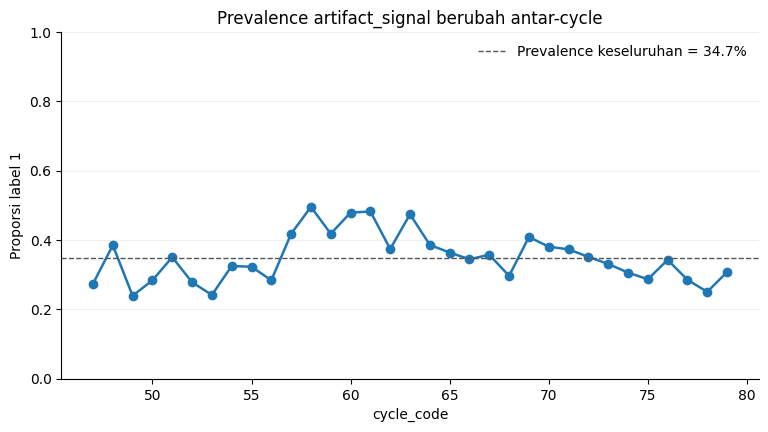

In [8]:
cycle_summary = (
    train.groupby("cycle_code", as_index=False)
    .agg(rows=("artifact_signal", "size"), positive_rate=("artifact_signal", "mean"))
)
fig, ax = plt.subplots()
ax.plot(cycle_summary.cycle_code, cycle_summary.positive_rate, marker="o", linewidth=1.8, color="#1f77b4")
ax.axhline(train.artifact_signal.mean(), color="#555555", linestyle="--", linewidth=1,
           label=f"Prevalence keseluruhan = {train.artifact_signal.mean():.1%}")
ax.set(title="Prevalence artifact_signal berubah antar-cycle", xlabel="cycle_code", ylabel="Proporsi label 1")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
early_cycles = cycle_summary.head(3).set_index("cycle_code").add_prefix("awal_")
late_cycles = cycle_summary.tail(3).set_index("cycle_code").add_prefix("akhir_")
display(pd.concat([early_cycles, late_cycles], axis=1))
plt.show()

## 3. EDA individual: teks kosong dan terisi

**Apakah persentase laporan berlabel `artifact_signal = 1` berbeda antara `signal_stream` kosong dan terisi, setelah mempertimbangkan waktu dan volume laporan?**

Sumber: official Classification Train.

### EDA 1. Data dan metode

Teks **kosong** berarti null, string kosong, atau hanya spasi. Waktu memakai `cycle_code`; volume memakai `text_load`, bukan jumlah token.

Perbandingan disesuaikan dengan memberi bobot yang sama pada kelompok waktu/volume untuk kedua status. Bobot mengikuti jumlah baris pada kelompok yang didukung. Minimum **20 baris per status per kelompok**. Rentang volume memakai kuantil tanpa label; ini penyesuaian kasar, bukan pencocokan nilai persis.

In [9]:
from IPython.display import Markdown, display
eda_train_path = task_files("classification")["train"]
if eda_train_path is None:
    raise FileNotFoundError("Place official classification/Train.csv under TP2_DATA_DIR or data/raw/.")
eda_train = pd.read_csv(eda_train_path)
eda_analysis = prepare_availability_frame(eda_train, stream_missing_mask(eda_train))
assert len(eda_analysis) == len(eda_train)
assert set(eda_analysis["availability"].unique()) == {"present", "missing"}
assert eda_analysis["cycle_code"].min() == 47 and eda_analysis["cycle_code"].max() == 79
eda_COLORS = {"present": "#1f4e79", "missing": "#d17a22"}
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9, "axes.spines.top": False, "axes.spines.right": False})
print(f"Source: official Classification Train.csv | {len(eda_train):,} rows x {eda_train.shape[1]} columns | cycles {eda_analysis.cycle_code.min()}–{eda_analysis.cycle_code.max()}")

Source: official Classification Train.csv | 50,608 rows x 19 columns | cycles 47–79


### EDA 2. Gambaran data

In [10]:
eda_grouped = prevalence_table(eda_analysis, ['availability']).set_index('availability').loc[['present', 'missing']]
eda_overview = pd.DataFrame({'Baris (n)': eda_grouped['n'].astype(int), 'artifact_signal = 1 (n)': eda_grouped['positive'].astype(int), 'Proporsi artifact (%)': eda_grouped['prevalence'] * 100, 'text_load median': eda_analysis.groupby('availability')['text_load'].median().loc[['present', 'missing']], 'text_load Q1': eda_analysis.groupby('availability')['text_load'].quantile(0.25).loc[['present', 'missing']], 'text_load Q3': eda_analysis.groupby('availability')['text_load'].quantile(0.75).loc[['present', 'missing']]})
eda_overview.index.name = 'Availability'
display(eda_overview.round(2))
print(f'Total Train {len(eda_analysis):,}; label positif {eda_analysis.artifact_signal.sum():,} ({eda_analysis.artifact_signal.mean():.2%}); cycle unik {eda_analysis.cycle_code.nunique()}.')

,Baris (n),artifact_signal = 1 (n),Proporsi artifact (%),text_load median,text_load Q1,text_load Q3
Availability,,,,,,
present,47204,16272,34.47,31.78,27.70,36.92
missing,3404,1298,38.13,21.81,20.55,23.79


Total Train 50,608; label positif 17,570 (34.72%); cycle unik 33.


Teks kosong hanya mencakup 6,73% laporan. Ukuran kelompok yang jauh berbeda perlu diperhatikan saat membaca persentase dan ketidakpastiannya.

### EDA 3. Perbandingan awal

Error bar adalah interval Wilson 95% masing-masing kelompok, bukan interval selisihnya.

,Ketersediaan,artifact_signal = 1 (n),Denominator (n),Proporsi (%),Wilson 95% bawah (%),Wilson 95% atas (%)
0,present,16272,47204,34.47,34.04,34.90
1,missing,1298,3404,38.13,36.51,39.78


Proporsi artifact pada Train adalah **34.47%** saat stream tersedia dan **38.13%** saat missing. Selisih missing − present adalah **+3.66 poin persentase (pp)**.

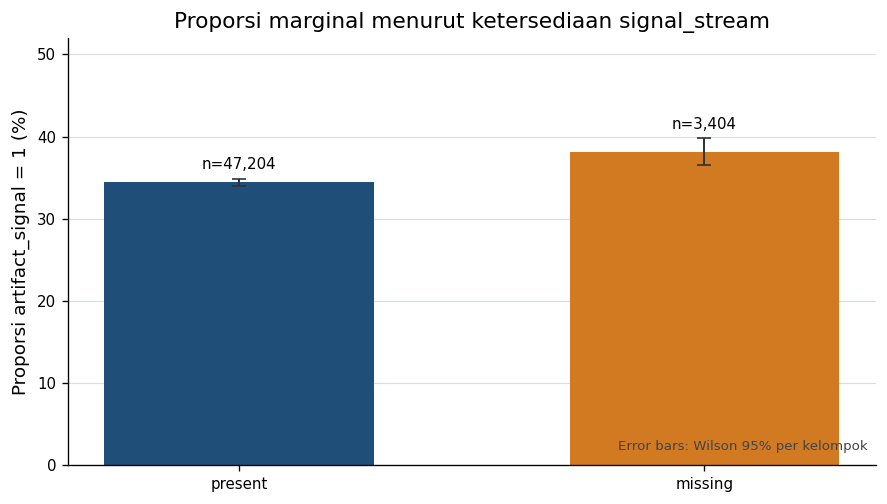

In [11]:
eda_marginal_rows = []
for eda_availability in ('present', 'missing'):
    eda_part = eda_analysis.loc[eda_analysis.availability.eq(eda_availability)]
    eda_successes, eda_n = (int(eda_part.artifact_signal.sum()), int(len(eda_part)))
    eda_low, eda_high = wilson_interval(eda_successes, eda_n)
    eda_marginal_rows.append({'Ketersediaan': eda_availability, 'artifact_signal = 1 (n)': eda_successes, 'Denominator (n)': eda_n, 'Proporsi (%)': 100 * eda_successes / eda_n, 'Wilson 95% bawah (%)': 100 * eda_low, 'Wilson 95% atas (%)': 100 * eda_high})
eda_marginal = pd.DataFrame(eda_marginal_rows)
eda_marginal_indexed = eda_marginal.set_index('Ketersediaan')
eda_marginal_gap_pp = eda_marginal_indexed.loc['missing', 'Proporsi (%)'] - eda_marginal_indexed.loc['present', 'Proporsi (%)']
display(eda_marginal.round(2))
display(Markdown(f"Proporsi artifact pada Train adalah **{eda_marginal_indexed.loc['present', 'Proporsi (%)']:.2f}%** saat stream tersedia dan **{eda_marginal_indexed.loc['missing', 'Proporsi (%)']:.2f}%** saat missing. Selisih missing − present adalah **{eda_marginal_gap_pp:+.2f} poin persentase (pp)**."))
eda_fig, eda_ax = plt.subplots(figsize=(7.5, 4.3))
eda_x = np.arange(len(eda_marginal))
eda_rates = eda_marginal['Proporsi (%)'].to_numpy()
eda_lower = eda_rates - eda_marginal['Wilson 95% bawah (%)'].to_numpy()
eda_upper = eda_marginal['Wilson 95% atas (%)'].to_numpy() - eda_rates
eda_ax.bar(eda_x, eda_rates, color=[eda_COLORS[eda_name] for eda_name in eda_marginal['Ketersediaan']], width=0.58, zorder=2)
eda_ax.errorbar(eda_x, eda_rates, yerr=np.vstack([eda_lower, eda_upper]), fmt='none', ecolor='#30343b', capsize=4, lw=1.2, zorder=3)
for eda_i, eda_row in eda_marginal.iterrows():
    eda_ax.text(eda_i, eda_row['Wilson 95% atas (%)'] + 1.2, f"n={int(eda_row['Denominator (n)']):,}", ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_marginal['Ketersediaan'])
eda_ax.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax.set_title('Proporsi marginal menurut ketersediaan signal_stream')
eda_ax.set_ylim(0, 52)
eda_ax.grid(axis='y', color='#d9dde3', linewidth=0.7, zorder=0)
eda_ax.text(0.99, 0.03, 'Error bars: Wilson 95% per kelompok', transform=eda_ax.transAxes, ha='right', va='bottom', fontsize=8, color='#40444b')
eda_fig.tight_layout()
plt.show()

Label 1 lebih sering muncul pada kelompok kosong, dengan selisih +3,66 pp. Ini belum memperhitungkan perbedaan waktu dan volume laporan.

### EDA 4. Perubahan sepanjang waktu

,Present n,Present (%),Missing n,Missing (%),Gap missing − present (pp)
period,,,,,
47–57,12537,30.78,1009,28.94,-1.84
58–68,15664,40.37,1072,50.37,10.01
69–79,19003,32.05,1323,35.22,3.18


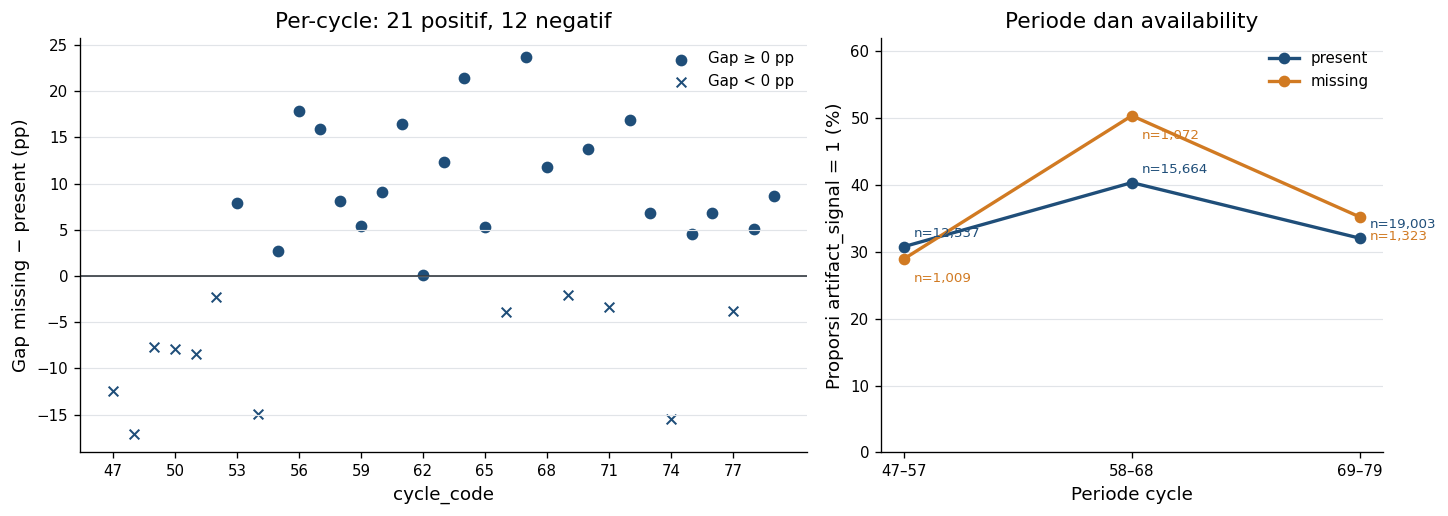

Gap per periode ialah **-1.84 pp**, **+10.01 pp**, dan **+3.18 pp**. Pada cycle dengan n≥20 untuk masing-masing status, 21/33 gap positif dan 12/33 negatif; rentangnya -17.04 sampai +23.73 pp.

In [12]:
eda_period_prevalence = prevalence_table(eda_analysis, ['period', 'availability'])
eda_period_pivot = eda_period_prevalence.pivot(index='period', columns='availability', values='prevalence').loc[['47–57', '58–68', '69–79']]
eda_period_n = eda_period_prevalence.pivot(index='period', columns='availability', values='n').loc[eda_period_pivot.index]
eda_period_summary = pd.DataFrame({'Present n': eda_period_n['present'].astype(int), 'Present (%)': 100 * eda_period_pivot['present'], 'Missing n': eda_period_n['missing'].astype(int), 'Missing (%)': 100 * eda_period_pivot['missing'], 'Gap missing − present (pp)': 100 * (eda_period_pivot['missing'] - eda_period_pivot['present'])})
display(eda_period_summary.round(2))
eda_cycle_prevalence = prevalence_table(eda_analysis, ['cycle_code', 'availability'])
eda_cycle_rates = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='prevalence')
eda_cycle_n = eda_cycle_prevalence.pivot(index='cycle_code', columns='availability', values='n')
eda_cycle_gap = 100 * (eda_cycle_rates['missing'] - eda_cycle_rates['present'])
eda_cycle_supported = eda_cycle_n['missing'].ge(20) & eda_cycle_n['present'].ge(20)
assert eda_cycle_supported.all(), 'Exact-cycle graph must not include unsupported groups'
eda_positive_cycles = int((eda_cycle_gap > 0).sum())
eda_negative_cycles = int((eda_cycle_gap < 0).sum())
eda_fig, (eda_ax_cycle, eda_ax_period) = plt.subplots(1, 2, figsize=(12.2, 4.4), gridspec_kw={'width_ratios': [1.45, 1]})
for eda_marker, eda_condition, eda_label in [('o', eda_cycle_gap >= 0, 'Gap ≥ 0 pp'), ('x', eda_cycle_gap < 0, 'Gap < 0 pp')]:
    eda_ax_cycle.scatter(eda_cycle_gap.index[eda_condition], eda_cycle_gap.loc[eda_condition], marker=eda_marker, s=34, color=eda_COLORS['present'], label=eda_label, linewidths=1.2)
eda_ax_cycle.axhline(0, color='#343a40', lw=1)
eda_ax_cycle.set_xticks(np.arange(47, 80, 3))
eda_ax_cycle.set_xlabel('cycle_code')
eda_ax_cycle.set_ylabel('Gap missing − present (pp)')
eda_ax_cycle.set_title(f'Per-cycle: {eda_positive_cycles} positif, {eda_negative_cycles} negatif')
eda_ax_cycle.legend(frameon=False, loc='best')
eda_ax_cycle.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_period_x = np.arange(len(eda_period_pivot))
for eda_availability in ('present', 'missing'):
    eda_values = 100 * eda_period_pivot[eda_availability].to_numpy()
    eda_ax_period.plot(eda_period_x, eda_values, marker='o', lw=2, color=eda_COLORS[eda_availability], label=eda_availability)
    for eda_j, (eda_value, eda_n) in enumerate(zip(eda_values, eda_period_n[eda_availability].to_numpy())):
        eda_offset = (6, 6) if eda_availability == 'present' else (6, -14)
        eda_ax_period.annotate(f'n={int(eda_n):,}', (eda_j, eda_value), xytext=eda_offset, textcoords='offset points', fontsize=8, color=eda_COLORS[eda_availability])
eda_ax_period.set_xticks(eda_period_x, eda_period_pivot.index)
eda_ax_period.set_xlabel('Periode cycle')
eda_ax_period.set_ylabel('Proporsi artifact_signal = 1 (%)')
eda_ax_period.set_title('Periode dan availability')
eda_ax_period.set_ylim(0, 62)
eda_ax_period.legend(frameon=False)
eda_ax_period.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Gap per periode ialah **{eda_period_summary.iloc[0]['Gap missing − present (pp)']:+.2f} pp**, **{eda_period_summary.iloc[1]['Gap missing − present (pp)']:+.2f} pp**, dan **{eda_period_summary.iloc[2]['Gap missing − present (pp)']:+.2f} pp**. Pada cycle dengan n≥20 untuk masing-masing status, {eda_positive_cycles}/{len(eda_cycle_gap)} gap positif dan {eda_negative_cycles}/{len(eda_cycle_gap)} negatif; rentangnya {eda_cycle_gap.min():+.2f} sampai {eda_cycle_gap.max():+.2f} pp."))

Gap positif pada 21 dari 33 cycle, tetapi negatif pada 12 lainnya. Periode tengah menunjukkan perbedaan terbesar; satu angka agregat menyembunyikan variasi ini.

### EDA 5. Perbedaan volume

,n,minimum,q1,median,q3,maximum
availability,,,,,,
present,47204,20.65,27.70,31.78,36.92,98.06
missing,3404,16.34,20.55,21.81,23.79,77.52


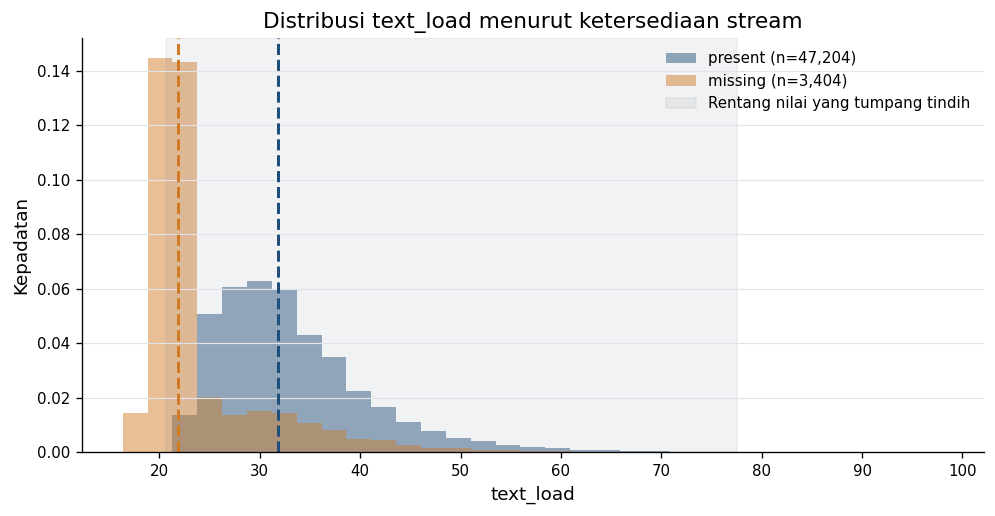

Median text_load adalah **31.78** saat stream tersedia dan **21.81** saat missing. Rentang nilai yang sama-sama teramati adalah **20.65–77.52**; di luarnya terdapat 906 baris missing dan 65 baris present.

In [13]:
eda_text_summary = eda_analysis.groupby('availability')['text_load'].agg(n='size', minimum='min', q1=lambda eda_x: eda_x.quantile(0.25), median='median', q3=lambda eda_x: eda_x.quantile(0.75), maximum='max').loc[['present', 'missing']]
eda_overlap_low = max(eda_text_summary.loc['present', 'minimum'], eda_text_summary.loc['missing', 'minimum'])
eda_overlap_high = min(eda_text_summary.loc['present', 'maximum'], eda_text_summary.loc['missing', 'maximum'])
eda_outside_missing = int((eda_analysis.availability.eq('missing') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
eda_outside_present = int((eda_analysis.availability.eq('present') & ~eda_analysis.text_load.between(eda_overlap_low, eda_overlap_high)).sum())
display(eda_text_summary.round(2))
eda_fig, eda_ax = plt.subplots(figsize=(8.4, 4.4))
eda_bins = np.linspace(eda_analysis.text_load.min(), eda_analysis.text_load.max(), 34)
for eda_availability in ('present', 'missing'):
    eda_values = eda_analysis.loc[eda_analysis.availability.eq(eda_availability), 'text_load']
    eda_ax.hist(eda_values, bins=eda_bins, density=True, alpha=0.48, color=eda_COLORS[eda_availability], label=f'{eda_availability} (n={len(eda_values):,})')
    eda_ax.axvline(eda_values.median(), color=eda_COLORS[eda_availability], lw=1.8, linestyle='--')
eda_ax.axvspan(eda_overlap_low, eda_overlap_high, color='#78828f', alpha=0.1, label='Rentang nilai yang tumpang tindih')
eda_ax.set_xlabel('text_load')
eda_ax.set_ylabel('Kepadatan')
eda_ax.set_title('Distribusi text_load menurut ketersediaan stream')
eda_ax.legend(frameon=False)
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_fig.tight_layout()
plt.show()
display(Markdown(f"Median text_load adalah **{eda_text_summary.loc['present', 'median']:.2f}** saat stream tersedia dan **{eda_text_summary.loc['missing', 'median']:.2f}** saat missing. Rentang nilai yang sama-sama teramati adalah **{eda_overlap_low:.2f}–{eda_overlap_high:.2f}**; di luarnya terdapat {eda_outside_missing:,} baris missing dan {eda_outside_present:,} baris present."))

Median `text_load` kelompok kosong 21,81, sedangkan kelompok terisi 31,78. Komposisi volume yang berbeda menjadi alasan untuk membandingkan kelompok waktu/volume yang lebih setara.

### EDA 6. Menyamakan komposisi

Bandingkan hasil awal dengan penyesuaian setiap cycle serta tiga periode x 5/10 kelompok volume. **Gap = persentase kosong - terisi**, dalam poin persentase (pp). Coverage menunjukkan bagian data yang memenuhi minimum support.

In [14]:
eda_cycle_standardized, eda_cycle_cells = standardized_contrast(eda_analysis, ['cycle_code'], min_support=20)
eda_q5_frame, eda_q5_edges = add_global_quantile_bins(eda_analysis, 5)
eda_period_q5, eda_period_q5_cells = standardized_contrast(eda_q5_frame, ['period', 'text_load_q5'], min_support=20)
eda_q10_frame, eda_q10_edges = add_global_quantile_bins(eda_analysis, 10)
eda_period_q10, eda_period_q10_cells = standardized_contrast(eda_q10_frame, ['period', 'text_load_q10'], min_support=20)
eda_comparison_rows = [{'Kontras': 'Marginal (seluruh Train)', 'Present (%)': eda_marginal_indexed.loc['present', 'Proporsi (%)'], 'Missing (%)': eda_marginal_indexed.loc['missing', 'Proporsi (%)'], 'Gap missing − present (pp)': eda_marginal_gap_pp, 'Sel didukung': '—', 'Baris present tercakup': int(eda_analysis.availability.eq('present').sum()), 'Baris missing tercakup': int(eda_analysis.availability.eq('missing').sum()), 'Coverage keseluruhan (%)': 100.0}]
for eda_label, eda_result in [('Exact cycle', eda_cycle_standardized), ('Periode × kuantil text_load (5)', eda_period_q5), ('Periode × kuantil text_load (10)', eda_period_q10)]:
    eda_comparison_rows.append({'Kontras': eda_label, 'Present (%)': 100 * eda_result['standardized_prevalence']['present'], 'Missing (%)': 100 * eda_result['standardized_prevalence']['missing'], 'Gap missing − present (pp)': eda_result['standardized_missing_minus_present_pp'], 'Sel didukung': f"{eda_result['cells_supported']}/{eda_result['cells_total']}", 'Baris present tercakup': eda_result['covered_rows_by_availability']['present'], 'Baris missing tercakup': eda_result['covered_rows_by_availability']['missing'], 'Coverage keseluruhan (%)': 100 * eda_result['coverage_all_rows']})
eda_contrasts = pd.DataFrame(eda_comparison_rows)
display(eda_contrasts.round(2))
eda_support_by_group = pd.DataFrame([{'Kontras': 'Exact cycle', 'Coverage present (%)': 100 * eda_cycle_standardized['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_cycle_standardized['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 5', 'Coverage present (%)': 100 * eda_period_q5['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q5['coverage_by_availability']['missing']}, {'Kontras': 'Periode × kuantil 10', 'Coverage present (%)': 100 * eda_period_q10['coverage_by_availability']['present'], 'Coverage missing (%)': 100 * eda_period_q10['coverage_by_availability']['missing']}])
display(eda_support_by_group.round(2))
print(f'Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin={len(eda_q5_edges) - 1}; 10-bin={len(eda_q10_edges) - 1}.')

,Kontras,Present (%),Missing (%),Gap missing − present (pp),Sel didukung,Baris present tercakup,Baris missing tercakup,Coverage keseluruhan (%)
0,Marginal (seluruh Train),34.47,38.13,3.66,—,47204,3404,100.00
1,Exact cycle,34.47,38.43,3.96,33/33,47204,3404,100.00
2,Periode × kuantil text_load (5),35.17,32.87,-2.30,15/15,47204,3404,100.00
3,Periode × kuantil text_load (10),35.52,33.36,-2.15,28/30,44368,3372,94.33


,Kontras,Coverage present (%),Coverage missing (%)
0,Exact cycle,100.00,100.00
1,Periode × kuantil 5,100.00,100.00
2,Periode × kuantil 10,93.99,99.06


Minimum support: 20 baris per availability per sel. Jumlah interval kuantil: 5-bin=5; 10-bin=10.


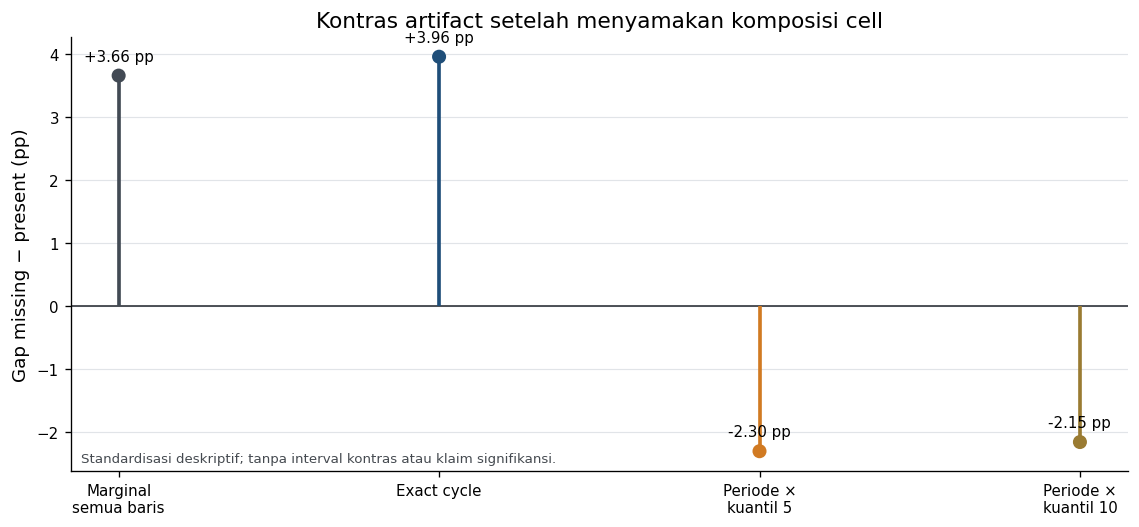

In [15]:
eda_fig, eda_ax = plt.subplots(figsize=(9.6, 4.5))
eda_labels = ['Marginal\nsemua baris', 'Exact cycle', 'Periode ×\nkuantil 5', 'Periode ×\nkuantil 10']
eda_gaps = eda_contrasts['Gap missing − present (pp)'].to_numpy()
eda_colors = ['#424a54', '#1f4e79', '#d17a22', '#9a7b32']
eda_x = np.arange(len(eda_gaps))
eda_ax.axhline(0, color='#30343b', lw=1)
eda_ax.vlines(eda_x, 0, eda_gaps, color=eda_colors, lw=2.2)
eda_ax.scatter(eda_x, eda_gaps, color=eda_colors, s=55, zorder=3)
for eda_i, eda_row in eda_contrasts.iterrows():
    eda_value = eda_row['Gap missing − present (pp)']
    eda_ax.annotate(f'{eda_value:+.2f} pp', (eda_i, eda_value), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=9)
eda_ax.set_xticks(eda_x, eda_labels)
eda_ax.set_ylabel('Gap missing − present (pp)')
eda_ax.set_title('Kontras artifact setelah menyamakan komposisi cell')
eda_ax.grid(axis='y', color='#e1e4e8', linewidth=0.7)
eda_ax.text(0.01, 0.02, 'Standardisasi deskriptif; tanpa interval kontras atau klaim signifikansi.', transform=eda_ax.transAxes, fontsize=8, color='#454a50')
eda_fig.tight_layout()
plt.show()

Menyamakan cycle saja tidak membalik arah gap, sedangkan penyesuaian periode dan volume membalikkannya. Hasil 5 dan 10 kelompok memiliki arah serupa, dengan coverage lebih rendah pada 10 kelompok.

### EDA 7. Interpretasi dan batasan

In [16]:
display(Markdown('\n\n'.join([
    f"Gap awal {eda_marginal_gap_pp:+.2f} pp; setelah penyesuaian cycle {eda_cycle_standardized['standardized_missing_minus_present_pp']:+.2f} pp; periode dan volume {eda_period_q5['standardized_missing_minus_present_pp']:+.2f} pp (5 kelompok) dan {eda_period_q10['standardized_missing_minus_present_pp']:+.2f} pp (10 kelompok).",
    f"Minimum 20 baris per status/kelompok. Pemeriksaan 10 kelompok mencakup {eda_period_q10['supported_rows_total']:,}/{len(eda_analysis):,} baris ({eda_period_q10['coverage_all_rows']:.2%}); {eda_period_q10['cells_supported']}/{eda_period_q10['cells_total']} kelompok didukung.",
    "Kelompok volume masih kasar dan faktor lain belum dikontrol. Routing berasal dari diagnosis model terdahulu; hasil EDA ini tidak membuktikan bahwa status teks menyebabkan label atau kenaikan performa."
])))

Gap awal +3.66 pp; setelah penyesuaian cycle +3.96 pp; periode dan volume -2.30 pp (5 kelompok) dan -2.15 pp (10 kelompok).

Minimum 20 baris per status/kelompok. Pemeriksaan 10 kelompok mencakup 47,740/50,608 baris (94.33%); 28/30 kelompok didukung.

Kelompok volume masih kasar dan faktor lain belum dikontrol. Routing berasal dari diagnosis model terdahulu; hasil EDA ini tidak membuktikan bahwa status teks menyebabkan label atau kenaikan performa.

### EDA 8. Kesimpulan

Ada perbedaan proporsi label, tetapi arahnya bergantung pada cara laporan dibandingkan. Pada seluruh data, teks kosong memiliki proporsi label 1 **38,13%**, dibanding **34,47%** pada teks terisi: gap **+3,66 pp**. Setelah komposisi setiap cycle disamakan, gap tetap positif **+3,96 pp** dengan seluruh **33 cycle dan 100% baris** didukung.

Ketika periode dan kelompok volume disamakan bersama, gap berbalik menjadi **-2,30 pp** pada 5 kelompok volume (**100% coverage**) dan **-2,15 pp** pada 10 kelompok (**94,33% coverage; 28/30 strata**). Jadi, pembalikan arah muncul pada penyesuaian gabungan waktu dan volume, bukan pada waktu saja.

Status teks kosong tidak cukup untuk menyimpulkan proporsi artifact tanpa memperhatikan komposisi laporan. Penyesuaian masih memakai rentang volume yang kasar; hasil ini bersifat deskriptif, tidak membuktikan sebab-akibat, dan belum memastikan pola yang sama pada Test.

## 4. Perkembangan pendekatan

Kode berikut hanya nama eksperimen, bukan algoritme baru. **HGB** adalah HistGradientBoosting, yaitu kumpulan pohon yang dilatih bertahap; **LR** adalah Logistic Regression.

| Nama yang dipakai | Kode riset | Fitur dan cara kerja |
|---|---|---|
| HGB terstruktur | C1_B | Fitur numerik/kategori, tanpa isi teks |
| LR gabungan | C2_B | Fitur terstruktur + TF-IDF teks |
| Routing | C4_HGB | LR gabungan saat teks terisi; HGB terstruktur saat kosong |

1. Majority dan model sederhana sebagai baseline.
2. LR/HGB dengan fitur terstruktur.
3. TF-IDF dan hybrid C2_B untuk menambah informasi teks.
4. C4_HGB mengatasi kelemahan hybrid saat teks kosong melalui routing.

Tabel berikut berasal dari eksperimen historis terverifikasi. Primary menggabungkan enam evaluasi dengan horizon 4 cycle; H12 memakai horizon 12 cycle. Sebagian barisnya sama, sehingga kedua hasil bukan bukti independen. TF-IDF memakai unigram-bigram, maksimal 20.000 fitur, `min_df=3`, dan sublinear TF.

### Asal hasil perbandingan

Tabel historis merangkum eksperimen sebelumnya dan disertakan langsung di notebook. Tabel ini menjadi pembanding; evaluasi temporal di bagian berikut tetap dilatih dan dihitung ulang dari data mentah.

,metode,Primary Macro F1,H12 Macro F1
recipe,,,
Majority,Majority,0.38938,0.38938
LR dua fitur,LR impact + EF,0.38938,0.38938
LR terstruktur,LR structured,0.71453,0.67679
HGB terstruktur,HGB structured,0.73102,0.68906
LR teks,TF-IDF LR,0.80139,0.78192
LR gabungan,Hybrid LR,0.82063,0.78858
Routing,Hybrid + HGB availability routing,0.82548,0.79681


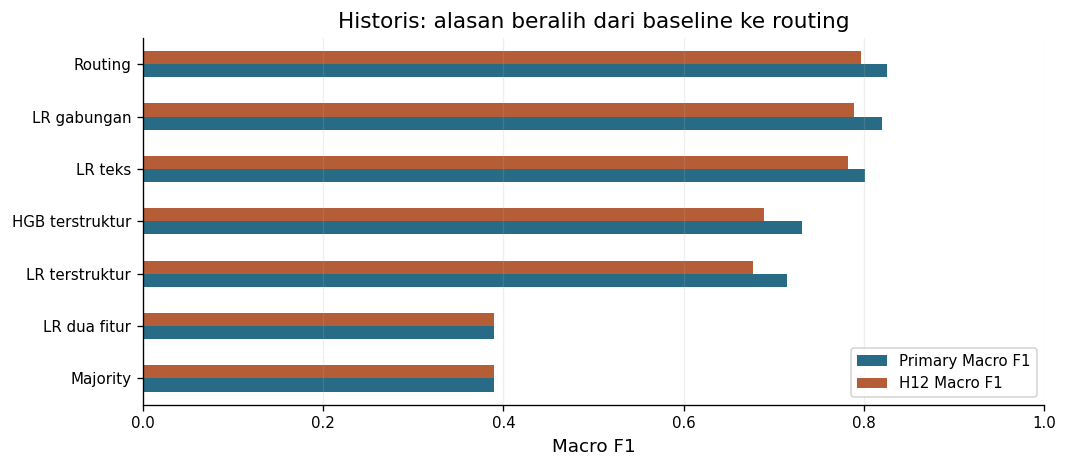

policy                  fixed_0.5  inner_pooled
recipe      keluarga                           
LR gabungan H12 pooled     0.7886        0.7924
            Primary        0.8206        0.8188
Routing     H12 pooled     0.7968        0.7998
            Primary        0.8255        0.8236

,primary Macro F1,H12 Macro F1,primary stream-present F1,primary stream-missing F1,H12 stream-present F1,H12 stream-missing F1
recipe,,,,,,
LR gabungan,0.8206,0.7886,0.8286,0.7104,0.8005,0.6305
Routing fallback LR,0.8242,0.7945,0.8286,0.7596,0.8005,0.7085
Routing,0.8255,0.7968,0.8286,0.7817,0.8005,0.7450


In [17]:
# These compact historical reference values are embedded for comparison only.
# Source artifacts and SHA-256 are listed below; no reports/ or experiment files are read at runtime.
HISTORICAL_CLASSIFICATION = {'feature_sets': {'two': ['impact_load', 'entry_friction'],
                  'ef': ['entry_friction'],
                  'structured': ['impact_load',
                                 'entry_friction',
                                 'cycle_code',
                                 'scope_pressure',
                                 'text_load',
                                 'scope_trace',
                                 'org_spread',
                                 'module_spread',
                                 'telemetry_flag',
                                 'org_code',
                                 'module_code',
                                 'pattern_code'],
                  'text': ['signal_stream'],
                  'hybrid': ['impact_load',
                             'entry_friction',
                             'cycle_code',
                             'scope_pressure',
                             'text_load',
                             'scope_trace',
                             'org_spread',
                             'module_spread',
                             'telemetry_flag',
                             'org_code',
                             'module_code',
                             'pattern_code',
                             'signal_stream']},
 'r1_primary': {'C0_A': {'metrics': {'macro_f1': 0.38938207136640557}},
                'C0_C': {'metrics': {'macro_f1': 0.38938207136640557}},
                'C1_A': {'metrics': {'macro_f1': 0.7145252653352889}},
                'C1_B': {'metrics': {'macro_f1': 0.7310190201940008}},
                'C2_A': {'metrics': {'macro_f1': 0.8013882844693636}},
                'C2_B': {'metrics': {'macro_f1': 0.8206329781454547}}},
 'r1_h12': {'C0_A': {'metrics': {'macro_f1': 0.38938207136640557}},
            'C0_C': {'metrics': {'macro_f1': 0.38938207136640557}},
            'C1_A': {'metrics': {'macro_f1': 0.6767855702307287}},
            'C1_B': {'metrics': {'macro_f1': 0.6890587156405323}},
            'C2_A': {'metrics': {'macro_f1': 0.7819236858188459}},
            'C2_B': {'metrics': {'macro_f1': 0.7885811256706727}}},
 'r2_primary': {'C2_B': {'metrics': {'macro_f1': 0.8206329781454547},
                         'subgroups': {'stream_present': {'macro_f1': 0.8285552807187074},
                                       'stream_missing': {'macro_f1': 0.7104270679715272}}},
                'C4_LR': {'metrics': {'macro_f1': 0.8242080321167009},
                          'subgroups': {'stream_present': {'macro_f1': 0.8285552807187074},
                                        'stream_missing': {'macro_f1': 0.7596095298014476}}},
                'C4_HGB': {'metrics': {'macro_f1': 0.8254807111314647},
                           'subgroups': {'stream_present': {'macro_f1': 0.8285552807187074},
                                         'stream_missing': {'macro_f1': 0.781711759145506}}}},
 'r2_h12': {'C2_B': {'metrics': {'macro_f1': 0.7885811256706727},
                     'subgroups': {'stream_present': {'macro_f1': 0.800474200237395},
                                   'stream_missing': {'macro_f1': 0.6304593574930747}}},
            'C4_LR': {'metrics': {'macro_f1': 0.7945131102741163},
                      'subgroups': {'stream_present': {'macro_f1': 0.800474200237395},
                                    'stream_missing': {'macro_f1': 0.7085442884508135}}},
            'C4_HGB': {'metrics': {'macro_f1': 0.7968102588689854},
                       'subgroups': {'stream_present': {'macro_f1': 0.800474200237395},
                                     'stream_missing': {'macro_f1': 0.7450062481396054}}}},
 'history_r2': {'aggregate': {'primary': {'fixed_0.5': {'C2_B': {'metrics': {'macro_f1': 0.8206329781454547}},
                                                        'C4_HGB': {'metrics': {'macro_f1': 0.8254807111314647}}},
                                          'inner_pooled': {'C2_B': {'metrics': {'macro_f1': 0.8187574582171067}},
                                                           'C4_HGB': {'metrics': {'macro_f1': 0.8236066688271738}}}},
                              'secondary': {'fixed_0.5': {'C2_B': {'metrics': {'macro_f1': 0.7885811256706727}},
                                                          'C4_HGB': {'metrics': {'macro_f1': 0.7968102588689854}}},
                                            'inner_pooled': {'C2_B': {'metrics': {'macro_f1': 0.7924027082959779}},
                                                             'C4_HGB': {'metrics': {'macro_f1': 0.7998390469349026}}}}},
                'jobs': [{'model': 'C1_B',
                          'window': 'W6',
                          'probability_sha256': 'a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1cb708ddc208f613095',
                          'policies': {'fixed_0.5': {'metrics': {'macro_f1': 0.703700351612718}}}},
                         {'model': 'C2_B',
                          'window': 'W6',
                          'probability_sha256': '01a886bb391728b58cb3504946d620efabc4859ea55585d36b76028793feb1f4',
                          'policies': {'fixed_0.5': {'metrics': {'macro_f1': 0.8055709115215474}}}},
                         {'model': 'C4_HGB',
                          'window': 'W6',
                          'probability_sha256': 'fc83ef0c5be271e1f952c24e9d196f85144ada3c701a1c0a793767733b9d1130',
                          'policies': {'fixed_0.5': {'metrics': {'macro_f1': 0.810383724597016}}}}]},
 'round1_fit75': {'C1_B': {'probability_sha256': 'a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1cb708ddc208f613095'},
                  'C2_B': {'probability_sha256': '01a886bb391728b58cb3504946d620efabc4859ea55585d36b76028793feb1f4'}},
 'submission_manifest': {'task': 'classification',
                         'model': {'route': 'C4_HGB fixed availability route; present=C2_B hybrid '
                                            'LR; missing=C1_B structured HGB',
                                   'threshold': 0.5},
                         'kaggle_submission': {'status': 'COMPLETE',
                                               'reference': 57808225,
                                               'public_score': 0.82641,
                                               'private_score': None}},
 'provenance': {'experiments/classification_round1/protocol.json': 'cf2a129c5c6f555fb5d1f15d7ef65595abd4bb09a6913f55b4d96ac5cdfb6b80',
                'experiments/classification_round1/freeze.json': '9eb7a7156a8985aac815e17aead155604d669e20f22f1d51bacfae9f7f4f83c9',
                'experiments/classification_round2/freeze.json': 'f9887c960ecc9dd7aea20b9dcd9475ce30e8e2cab54c6af47665037e0198cf06',
                'reports/classification_round1/results.json': '3c2dc8d9a83d351e38eea3ea90da3b07fd4e037baa5d030ea16868db7ddfe666',
                'reports/classification_round2/results.json': '10bcbe0033b3a66a431bebf79ce5e9014b8cd4290e097228dd1eeada596e7414',
                'reports/classification_round1/fit_audits/fit75.json': '428a8f1530e0eadf288303721519e521ee9b14fc65bff84faf09aae5a08d4e2b',
                'reports/submissions/classification_initial_manifest.json': '3369ec1a73c98a276c65783bd2e71a3bdfc129cece8d48a035aee98846818974'}}
MODEL_LABELS = {"C0_A": "Majority", "C0_C": "LR dua fitur", "C1_A": "LR terstruktur", "C1_B": "HGB terstruktur", "C2_A": "LR teks", "C2_B": "LR gabungan", "C4_LR": "Routing fallback LR", "C4_HGB": "Routing"}
r1_primary = HISTORICAL_CLASSIFICATION['r1_primary']
r1_h12 = HISTORICAL_CLASSIFICATION['r1_h12']
r2_primary = HISTORICAL_CLASSIFICATION['r2_primary']
r2_h12 = HISTORICAL_CLASSIFICATION['r2_h12']
history_r2 = HISTORICAL_CLASSIFICATION['history_r2']
round1_fit75 = HISTORICAL_CLASSIFICATION['round1_fit75']
submission_manifest = HISTORICAL_CLASSIFICATION['submission_manifest']

names = {"C0_A":"Majority", "C0_C":"LR impact + EF", "C1_A":"LR structured",
         "C1_B":"HGB structured", "C2_A":"TF-IDF LR", "C2_B":"Hybrid LR"}
evolution_rows=[]
for recipe, label in names.items():
    evolution_rows.append({"recipe":recipe,"metode":label,
        "Primary Macro F1":r1_primary[recipe]["metrics"]["macro_f1"],
        "H12 Macro F1":r1_h12[recipe]["metrics"]["macro_f1"]})
evolution_rows.append({"recipe":"C4_HGB","metode":"Hybrid + HGB availability routing",
    "Primary Macro F1":r2_primary["C4_HGB"]["metrics"]["macro_f1"],
    "H12 Macro F1":r2_h12["C4_HGB"]["metrics"]["macro_f1"]})
evolution = pd.DataFrame(evolution_rows).set_index("recipe").rename(index=MODEL_LABELS).rename(index=MODEL_LABELS)
display(evolution.round(5))
ax=evolution[["Primary Macro F1","H12 Macro F1"]].plot.barh(color=["#276b86","#b45d36"],figsize=(9,4))
ax.set(title="Historis: alasan beralih dari baseline ke routing", xlabel="Macro F1", xlim=(0,1),ylabel="")
ax.legend(fontsize=9);ax.grid(axis="x",alpha=.2);plt.tight_layout();plt.show()

threshold_rows = []
for family, key in [("Primary", "primary"), ("H12 pooled", "secondary")]:
    for policy in ["fixed_0.5", "inner_pooled"]:
        cell = history_r2["aggregate"][key][policy]["C2_B"]
        threshold_rows.append({"recipe": MODEL_LABELS["C2_B"], "keluarga": family, "policy": policy,
                               "Macro F1": cell["metrics"]["macro_f1"]})
        route = history_r2["aggregate"][key][policy]["C4_HGB"]
        threshold_rows.append({"recipe": MODEL_LABELS["C4_HGB"], "keluarga": family, "policy": policy,
                               "Macro F1": route["metrics"]["macro_f1"]})
display(pd.DataFrame(threshold_rows).pivot_table(index=["recipe", "keluarga"], columns="policy",
                                                 values="Macro F1").round(4))

route_comparison = []
for recipe in ["C2_B", "C4_LR", "C4_HGB"]:
    primary = r2_primary[recipe]
    h12 = r2_h12[recipe]
    route_comparison.append({
        "recipe": MODEL_LABELS.get(recipe, recipe),
        "primary Macro F1": primary["metrics"]["macro_f1"],
        "H12 Macro F1": h12["metrics"]["macro_f1"],
        "primary stream-present F1": primary["subgroups"]["stream_present"]["macro_f1"],
        "primary stream-missing F1": primary["subgroups"]["stream_missing"]["macro_f1"],
        "H12 stream-present F1": h12["subgroups"]["stream_present"]["macro_f1"],
        "H12 stream-missing F1": h12["subgroups"]["stream_missing"]["macro_f1"],
    })
display(pd.DataFrame(route_comparison).set_index("recipe").rename(index=MODEL_LABELS).rename(index=MODEL_LABELS).round(4))

Model dua fitur dan majority masih lemah. Fitur structured menaikkan Macro F1 primary menjadi **0,7145 (LR)** dan **0,7310 (HGB)**; TF-IDF saja mencapai **0,8014**. Menggabungkan teks dan struktur pada LR gabungan (C2_B) mencapai **0,8206**, sehingga kedua jenis informasi saling melengkapi dalam eksperimen ini.

Namun LR gabungan (C2_B) lebih lemah pada teks kosong: Macro F1 subgroup **0,7104**, dibanding **0,7817** setelah memakai fallback HGB pada Routing (C4_HGB). Routing dipilih untuk menangani perbedaan tersebut sambil mempertahankan hybrid pada teks terisi. Hasil gabungan menjadi **0,8255 primary / 0,7968 H12**.

Pemilihan threshold dari inner history memperbaiki H12, tetapi menurunkan primary Routing (C4_HGB) dari **0,8255 menjadi 0,8236**. Karena manfaatnya tidak konsisten, keputusan tetap memakai threshold **0,50**.

## 5. Pipeline dan validasi temporal

Fit pada cycle 47-75, evaluasi 76-79. LR gabungan (C2_B) memakai structured + TF-IDF Logistic Regression dan HGB terstruktur (C1_B) memakai structured HGB. Imputasi, encoding, scaling, dan vocabulary hanya dipelajari dari fold fit.

In [18]:
# Siklus terakhir sebagai contoh temporal end-to-end; label validation tidak masuk ke fit.
FIT_CYCLES = (47, 75)
VALID_CYCLES = (76, 79)
feature_sets = CLASSIFICATION_FEATURE_SETS
X_STRUCTURED = list(feature_sets["structured"])
X_HYBRID = list(feature_sets["hybrid"])

fit_mask = train.cycle_code.between(*FIT_CYCLES)
valid_mask = train.cycle_code.between(*VALID_CYCLES)
fit_rows = np.flatnonzero(fit_mask.to_numpy())
valid_rows = np.flatnonzero(valid_mask.to_numpy())
assert len(np.intersect1d(fit_rows, valid_rows)) == 0
assert int(train.loc[fit_mask, "cycle_code"].max()) < int(train.loc[valid_mask, "cycle_code"].min())
assert train.loc[fit_mask, "artifact_signal"].nunique() == 2

X_fit_hybrid = train.loc[fit_mask, X_HYBRID].copy()
X_fit_structured = train.loc[fit_mask, X_STRUCTURED].copy()
y_fit = train.loc[fit_mask, "artifact_signal"].to_numpy(dtype=np.int8, copy=True)
X_valid_hybrid = train.loc[valid_mask, X_HYBRID].copy()
X_valid_structured = train.loc[valid_mask, X_STRUCTURED].copy()

c2b = build_round2_model({"id": "C2_B", "kind": "control", "source": "C2_B"})
c1b = build_round2_model({"id": "C1_B", "kind": "control", "source": "C1_B"})
with threadpool_limits(limits=2):
    c2b.fit(X_fit_hybrid, y_fit)
    probability_c2b = c2b.predict_proba(X_valid_hybrid)
    c1b.fit(X_fit_structured, y_fit)
    probability_c1b = c1b.predict_proba(X_valid_structured)

missing_valid = stream_missing_mask(X_valid_hybrid)
probability_c4hgb = np.where(missing_valid, probability_c1b, probability_c2b)
threshold = 0.50

# Open validation labels only after both fitted models have produced probabilities.
y_valid = train.loc[valid_mask, "artifact_signal"].to_numpy(dtype=np.int8, copy=True)
validation_cycles = train.loc[valid_mask, "cycle_code"].to_numpy(copy=True)
probabilities = {"C1_B": probability_c1b, "C2_B": probability_c2b, "C4_HGB": probability_c4hgb}
assert all(np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all() for p in probabilities.values())
assert len(y_valid) == len(valid_rows) == 8491
assert (int(train.loc[fit_mask].shape[0]), int(train.loc[fit_mask, "cycle_code"].min()),
        int(train.loc[fit_mask, "cycle_code"].max())) == (42117, 47, 75)
print(f"Fit: {len(fit_rows):,} rows, cycles {FIT_CYCLES[0]}–{FIT_CYCLES[1]}")
print(f"Validation: {len(valid_rows):,} rows, cycles {VALID_CYCLES[0]}–{VALID_CYCLES[1]}")
print(f"signal_stream kosong di validation: {int(missing_valid.sum()):,} ({missing_valid.mean():.2%})")
print("Threshold untuk seluruh hasil utama:", threshold)

Fit: 42,117 rows, cycles 47–75
Validation: 8,491 rows, cycles 76–79
signal_stream kosong di validation: 526 (6.19%)
Threshold untuk seluruh hasil utama: 0.5


### Pemeriksaan reproduksi

Imputasi, encoding, scaling, dan TF-IDF dipelajari di dalam fit. Hash prediksi dibandingkan dengan receipt historis W6 tanpa cache model pribadi.

In [19]:
round2_results = history_r2
round2_w6 = {
    job["model"]: job for job in round2_results["jobs"]
    if job.get("window") == "W6" and job.get("model") in {"C1_B", "C2_B", "C4_HGB"}
}
probability_hashes = {
    "C1_B": _array_digest(probability_c1b),
    "C2_B": _array_digest(probability_c2b),
    "C4_HGB": _array_digest(probability_c4hgb),
}
expected_hashes = {
    "C1_B": round1_fit75["C1_B"]["probability_sha256"],
    "C2_B": round1_fit75["C2_B"]["probability_sha256"],
    "C4_HGB": round2_w6["C4_HGB"]["probability_sha256"],
}
hash_checks = pd.DataFrame([
    {"model": name, "refit W6 probability SHA-256": probability_hashes[name],
     "verified historical SHA-256": expected_hashes[name],
     "identik": probability_hashes[name] == expected_hashes[name]}
    for name in probabilities
])
display(hash_checks[["model", "identik"]])
assert hash_checks["identik"].all(), "Fresh W6 predictions differ from the verified historical recipe."

audit_rows = []
for name, model in [("C2_B", c2b), ("C1_B", c1b)]:
    state = model.audit_state()
    audit_rows.append({"model": name, "fit rows": state["fit_rows"],
                       "input features": len(state["input_feature_names"]),
                       "state SHA-256": state.get("model_state_sha256", state.get("fit_fingerprint")),
                       "preprocessing fit-only": True})
display(pd.DataFrame(audit_rows))

,model,identik
0,C1_B,True
1,C2_B,True
2,C4_HGB,True


,model,fit rows,input features,state SHA-256,preprocessing fit-only
0,C2_B,42117,13,b2516813479876fb95457791ceab58b51fc2b58b60b84e...,True
1,C1_B,42117,12,f7b99ab8b68265b609eb9d13f24c9d59a77076b03c96b2...,True


## 6. Evaluasi model

,n,Macro F1,F1 kelas 0,F1 kelas 1,AP,positive aktual,positive prediksi
model,,,,,,,
HGB terstruktur,8491,0.7037,0.8368,0.5706,0.6376,0.2944,0.2563
LR gabungan,8491,0.8056,0.8886,0.7226,0.7756,0.2944,0.2786
Routing,8491,0.8104,0.8940,0.7268,0.7809,0.2944,0.2646


,model,kelas,support,precision,recall,F1
0,HGB terstruktur,0,5991,0.8154,0.8595,0.8368
1,HGB terstruktur,1,2500,0.6131,0.5336,0.5706
2,LR gabungan,0,5991,0.8789,0.8985,0.8886
3,LR gabungan,1,2500,0.7430,0.7032,0.7226
4,Routing,0,5991,0.8759,0.9129,0.8940
5,Routing,1,2500,0.7677,0.6900,0.7268


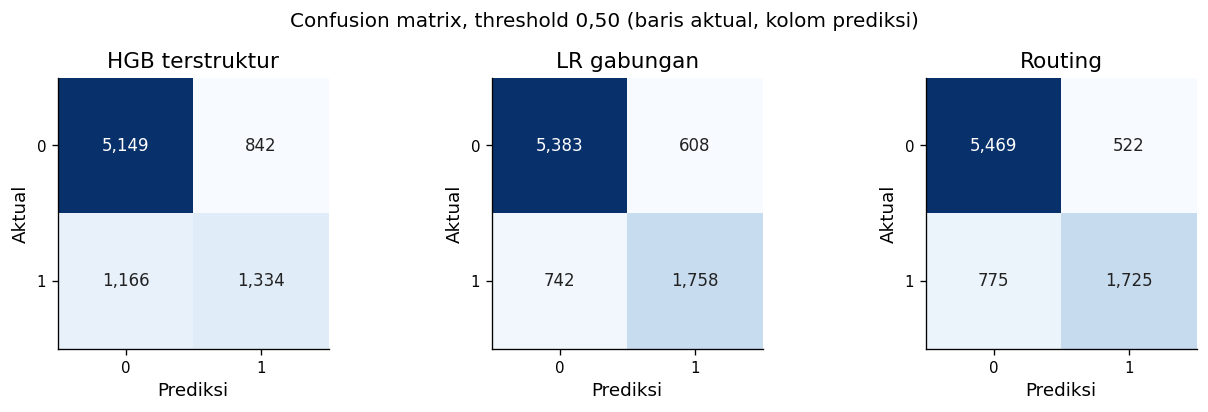

model,HGB terstruktur,LR gabungan,Routing
cycle,,,
76,0.7273,0.7937,0.7968
77,0.7268,0.7916,0.8014
78,0.6773,0.8115,0.8175
79,0.6762,0.8214,0.8213


,equal-cycle Macro F1
model,
HGB terstruktur,0.7019
LR gabungan,0.8046
Routing,0.8093


C1_B      0.703700
C2_B      0.805571
C4_HGB    0.810384
Name: Independent sklearn Macro F1, dtype: float64

INDEPENDENT_MACRO_F1_JSON={"C1_B": 0.703700351612718, "C2_B": 0.8055709115215474, "C4_HGB": 0.810383724597016}


In [20]:
def one_row_metrics(name, mask=None):
    if mask is None:
        mask = np.ones(len(y_valid), dtype=bool)
    result = binary_metrics(y_valid[mask], probabilities[name][mask], threshold)
    return result

metric_results = {name: one_row_metrics(name) for name in probabilities}
overall_rows = []
class_rows = []
for name, result in metric_results.items():
    m = result
    overall_rows.append({"model": MODEL_LABELS.get(name, name), "n": m["n"], "Macro F1": m["macro_f1"],
                         "F1 kelas 0": m["per_class"][0]["f1"], "F1 kelas 1": m["per_class"][1]["f1"],
                         "AP": m["average_precision"], "positive aktual": m["positive_rate"],
                         "positive prediksi": m["positive_prediction_rate"]})
    for cls in m["per_class"]:
        class_rows.append({"model": MODEL_LABELS.get(name, name), "kelas": cls["label"], "support": cls["support"],
                           "precision": cls["precision"], "recall": cls["recall"], "F1": cls["f1"]})
overall_table = pd.DataFrame(overall_rows).set_index("model")
display(overall_table.style.format("{:.4f}", subset=["Macro F1", "F1 kelas 0", "F1 kelas 1", "AP", "positive aktual", "positive prediksi"]))
display(pd.DataFrame(class_rows).style.format({"precision": "{:.4f}", "recall": "{:.4f}", "F1": "{:.4f}"}))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (name, result) in zip(axes, metric_results.items()):
    cm = np.asarray(result["confusion_matrix"])
    ax.imshow(cm, cmap="Blues")
    ax.set(title=MODEL_LABELS.get(name, name), xlabel="Prediksi", ylabel="Aktual", xticks=[0, 1], yticks=[0, 1])
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, f"{value:,}", ha="center", va="center",
                color="white" if value > cm.max() * 0.55 else "#222222")
fig.suptitle("Confusion matrix, threshold 0,50 (baris aktual, kolom prediksi)")
plt.tight_layout()
plt.show()

cycle_rows = []
for name, p in probabilities.items():
    for cycle in sorted(np.unique(validation_cycles)):
        mask = validation_cycles == cycle
        m = binary_metrics(y_valid[mask], p[mask], threshold)
        cycle_rows.append({"model": MODEL_LABELS.get(name, name), "cycle": int(cycle), "n": int(mask.sum()),
                           "Macro F1": m["macro_f1"], "prevalence": m["positive_rate"],
                           "positive prediksi": m["positive_prediction_rate"]})
cycle_table = pd.DataFrame(cycle_rows)
display(cycle_table.pivot(index="cycle", columns="model", values="Macro F1").round(4))
equal_cycle = cycle_table.groupby("model")["Macro F1"].mean().rename("equal-cycle Macro F1")
display(equal_cycle.to_frame().round(4))
from sklearn.metrics import f1_score
independent_macro_f1 = {}
for name, probability in probabilities.items():
    independent_macro_f1[name] = float(f1_score(y_valid, (probability >= 0.50).astype(np.int8), labels=[0, 1], average="macro", zero_division=0))
    assert np.isclose(independent_macro_f1[name], metric_results[name]["macro_f1"], rtol=0, atol=1e-12)
assert np.array_equal(probability_c4hgb[~missing_valid], probability_c2b[~missing_valid])
assert np.array_equal(probability_c4hgb[missing_valid], probability_c1b[missing_valid])
display(pd.Series(independent_macro_f1, name="Independent sklearn Macro F1"))
print("INDEPENDENT_MACRO_F1_JSON=" + json.dumps(independent_macro_f1, sort_keys=True))


Routing mengurangi false positive dari **608 menjadi 522**, tetapi true positive juga turun dari **1.758 menjadi 1.725** dibanding hybrid LR gabungan (C2_B). Jadi, peningkatan keputusan memiliki trade-off: lebih sedikit alarm salah dengan sedikit kehilangan deteksi positif.

model,HGB terstruktur,LR gabungan,Routing
kelompok,,,
EF0,0.6715,0.8033,0.8078
EF1,0.7354,0.7970,0.8011
stream kosong,0.7466,0.6775,0.7466
stream tersedia,0.7007,0.8147,0.8147


,kelompok,model,n,Macro F1,F1 kelas 0,F1 kelas 1,FP,FN
0,stream kosong,HGB terstruktur,526,0.7466,0.8502,0.6431,40,71
1,stream kosong,LR gabungan,526,0.6775,0.7363,0.6186,126,38
2,stream kosong,Routing,526,0.7466,0.8502,0.6431,40,71
3,stream tersedia,HGB terstruktur,7965,0.7007,0.8360,0.5654,802,1095
4,stream tersedia,LR gabungan,7965,0.8147,0.8968,0.7326,482,704
5,stream tersedia,Routing,7965,0.8147,0.8968,0.7326,482,704


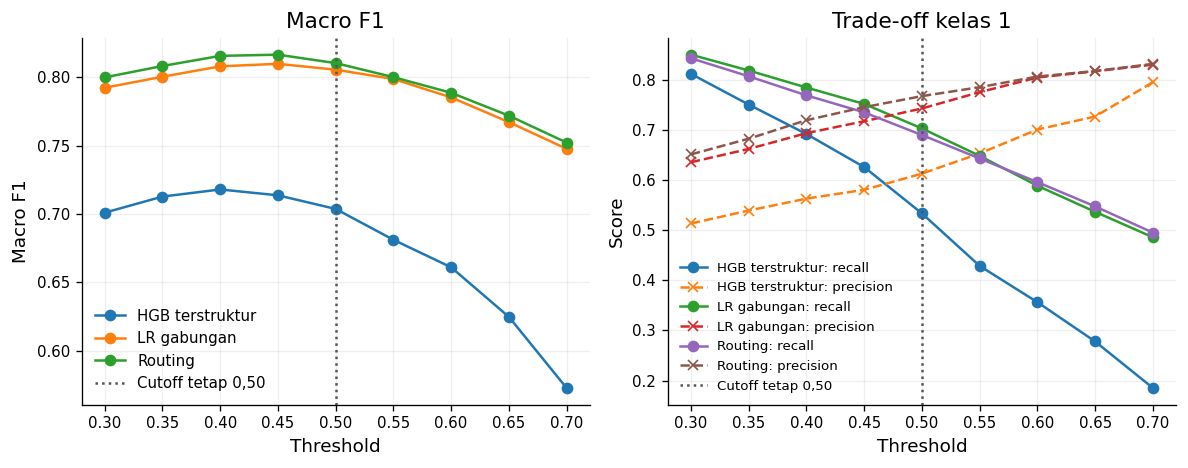

,model,threshold,Macro F1,precision class 1,recall class 1,positive prediction rate
4,HGB terstruktur,0.5,0.7037,0.6131,0.5336,0.2563
13,LR gabungan,0.5,0.8056,0.7430,0.7032,0.2786
22,Routing,0.5,0.8104,0.7677,0.6900,0.2646


In [21]:
subgroup_masks = {
    "stream kosong": missing_valid,
    "stream tersedia": ~missing_valid,
    "EF0": train.loc[valid_mask, "entry_friction"].eq(0).to_numpy(),
    "EF1": train.loc[valid_mask, "entry_friction"].eq(1).to_numpy(),
}
subgroup_rows = []
for group, mask in subgroup_masks.items():
    for name, p in probabilities.items():
        m = binary_metrics(y_valid[mask], p[mask], threshold)
        subgroup_rows.append({"kelompok": group, "model": MODEL_LABELS.get(name, name), "n": m["n"],
                              "Macro F1": m["macro_f1"], "F1 kelas 0": m["per_class"][0]["f1"],
                              "F1 kelas 1": m["per_class"][1]["f1"],
                              "FP": m["false_positive"], "FN": m["false_negative"]})
subgroup_table = pd.DataFrame(subgroup_rows)
display(subgroup_table.pivot(index="kelompok", columns="model", values="Macro F1").round(4))
display(subgroup_table[subgroup_table["kelompok"].str.startswith("stream")].round(4))

# Descriptive cutoff sensitivity on the same temporal validation block.
# This grid is not used to choose or replace the frozen 0.50 threshold.
threshold_rows = []
cutoff_grid = np.round(np.arange(0.30, 0.701, 0.05), 2)
for name, p in probabilities.items():
    for cutoff in cutoff_grid:
        m = binary_metrics(y_valid, p, float(cutoff))
        threshold_rows.append({"model": MODEL_LABELS.get(name, name), "threshold": cutoff, "Macro F1": m["macro_f1"],
                               "precision class 1": m["per_class"][1]["precision"],
                               "recall class 1": m["per_class"][1]["recall"],
                               "positive prediction rate": m["positive_prediction_rate"]})
threshold_table = pd.DataFrame(threshold_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, group in threshold_table.groupby("model"):
    axes[0].plot(group.threshold, group["Macro F1"], marker="o", label=name)
    axes[1].plot(group.threshold, group["recall class 1"], marker="o", label=f"{name}: recall")
    axes[1].plot(group.threshold, group["precision class 1"], marker="x", linestyle="--", label=f"{name}: precision")
for ax in axes:
    ax.axvline(0.50, color="#555555", linestyle=":", label="Cutoff tetap 0,50")
    ax.set_xlabel("Threshold")
    ax.grid(alpha=0.2)
axes[0].set(title="Macro F1", ylabel="Macro F1")
axes[1].set(title="Trade-off kelas 1", ylabel="Score")
axes[0].legend(frameon=False)
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
display(threshold_table[threshold_table.threshold.eq(0.50)].round(4))

Kurva threshold hanya diagnostik; keputusan tetap **0,50**.

### Recipe individual dan Kaggle

- Teks kosong: HGB terstruktur (C1_B) structured HGB.
- Teks terisi: LR gabungan (C2_B) structured + TF-IDF LR.
- Routing hanya memakai ketersediaan fitur; ID dan target tidak menjadi predictor.

Skor public di bawah berasal dari manifest submission historis, terpisah dari validasi temporal.

In [22]:
submission_manifest = HISTORICAL_CLASSIFICATION["submission_manifest"]
kaggle = submission_manifest["kaggle_submission"]
assert submission_manifest["task"] == "classification"
assert kaggle["status"] == "COMPLETE"
assert kaggle["reference"] == 57808225
assert float(kaggle["public_score"]) == 0.82641
candidate_id = "C4_HGB"
assert candidate_id in submission_manifest["model"]["route"]
assert float(submission_manifest["model"]["threshold"]) == 0.50
display(pd.DataFrame([{
    "kandidat": candidate_id,
    "threshold": submission_manifest["model"]["threshold"],
    "status Kaggle": kaggle["status"],
    "public score": kaggle["public_score"],
    "submission ref": kaggle["reference"],
    "private score tersedia": kaggle["private_score"] is not None,
}]))

historical_w6 = pd.DataFrame([
    {"model": name, "W6 probability SHA-256": round2_w6[name]["probability_sha256"],
     "Macro F1": round2_w6[name]["policies"]["fixed_0.5"]["metrics"]["macro_f1"]}
    for name in ["C1_B", "C2_B", "C4_HGB"]
])
fresh_w6 = pd.DataFrame([
    {"model": name, "fresh SHA-256": probability_hashes[name],
     "fresh Macro F1": metric_results[name]["macro_f1"]}
    for name in ["C1_B", "C2_B", "C4_HGB"]
])
display(historical_w6.merge(fresh_w6, on="model").round(6))

,kandidat,threshold,status Kaggle,public score,submission ref,private score tersedia
0,C4_HGB,0.5,COMPLETE,0.82641,57808225,False


,model,W6 probability SHA-256,Macro F1,fresh SHA-256,fresh Macro F1
0,C1_B,a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1...,0.703700,a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1...,0.703700
1,C2_B,01a886bb391728b58cb3504946d620efabc4859ea55585...,0.805571,01a886bb391728b58cb3504946d620efabc4859ea55585...,0.805571
2,C4_HGB,fc83ef0c5be271e1f952c24e9d196f85144ada3c701a1c...,0.810384,fc83ef0c5be271e1f952c24e9d196f85144ada3c701a1c...,0.810384


In [23]:
core_receipt = {
    "task": "classification", "fit_cycles": [47, 75], "validation_cycles": [76, 79],
    "fit_rows": len(fit_rows), "validation_rows": len(valid_rows), "threshold": 0.50,
    "metrics": {name: float(result["macro_f1"]) for name, result in metric_results.items()},
    "probability_sha256": probability_hashes,
    "matches_historical_predictions": bool(hash_checks["identik"].all()),
    "historical_primary_macro_f1": float(r2_primary["C4_HGB"]["metrics"]["macro_f1"]),
    "historical_h12_macro_f1": float(r2_h12["C4_HGB"]["metrics"]["macro_f1"]),
    "kaggle_public_macro_f1": float(submission_manifest["kaggle_submission"]["public_score"]),
    "fit_preprocessing_only_train": True, "test_used_in_core": False,
}
display(pd.Series(core_receipt, name="W6 replay receipt"))
print("CORE_RECEIPT_JSON=" + json.dumps(core_receipt, sort_keys=True))

task                                                                 classification
fit_cycles                                                                 [47, 75]
validation_cycles                                                          [76, 79]
fit_rows                                                                      42117
validation_rows                                                                8491
threshold                                                                       0.5
metrics                           {'C1_B': 0.703700351612718, 'C2_B': 0.80557091...
probability_sha256                {'C1_B': 'a21ba8ffa0396afe9f8d7ee78bbcccc5d602...
matches_historical_predictions                                                 True
historical_primary_macro_f1                                                0.825481
historical_h12_macro_f1                                                     0.79681
kaggle_public_macro_f1                                                      

CORE_RECEIPT_JSON={"fit_cycles": [47, 75], "fit_preprocessing_only_train": true, "fit_rows": 42117, "historical_h12_macro_f1": 0.7968102588689854, "historical_primary_macro_f1": 0.8254807111314647, "kaggle_public_macro_f1": 0.82641, "matches_historical_predictions": true, "metrics": {"C1_B": 0.703700351612718, "C2_B": 0.8055709115215474, "C4_HGB": 0.810383724597016}, "probability_sha256": {"C1_B": "a21ba8ffa0396afe9f8d7ee78bbcccc5d6024ade0037f1cb708ddc208f613095", "C2_B": "01a886bb391728b58cb3504946d620efabc4859ea55585d36b76028793feb1f4", "C4_HGB": "fc83ef0c5be271e1f952c24e9d196f85144ada3c701a1c0a793767733b9d1130"}, "task": "classification", "test_used_in_core": false, "threshold": 0.5, "validation_cycles": [76, 79], "validation_rows": 8491}


## 7. Melatih model akhir dan membuat prediksi Test

Evaluasi sebelumnya memisahkan data masa lalu untuk melatih model dan cycle berikutnya untuk mengukur error. Setelah pendekatan dipilih, model dilatih ulang memakai **seluruh 50.608 baris Train**, agar prediksi official Test memanfaatkan semua label yang tersedia. Tahap inilah yang disebut **refit penuh**.

Sel di bawah menjalankannya jika `RUN_FULL_TRAIN_INFERENCE = True`: seluruh preprocessing dipelajari ulang dari Train, kemudian model memprediksi Test dan menyimpan CSV lokal. Nilainya dibiarkan `False` saat demonstrasi agar tidak mengulang pembuatan file; **evaluasi temporal di bagian sebelumnya tetap dijalankan**.

Tahap ini tidak menghasilkan skor validasi baru karena label Test tidak tersedia. Angka public Kaggle yang ditampilkan berasal dari submission historis, bukan dihitung oleh sel ini.

In [24]:
RUN_FULL_TRAIN_INFERENCE = False
if RUN_FULL_TRAIN_INFERENCE:
    if DATA_FILES["test"] is None or DATA_FILES["sample"] is None:
        raise FileNotFoundError("Official Test.csv dan SampleSubmission.csv diperlukan untuk inference.")
    assert sha256_file(DATA_FILES['test']) == '4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57a91a5482867f6afe3c'
    assert sha256_file(DATA_FILES['sample']) == '889f97d69659a64945421d841dcf96e5813020606f29b2992d4b9560cecdcba7'
    test = pd.read_csv(DATA_FILES["test"])
    sample = pd.read_csv(DATA_FILES["sample"])
    assert list(sample.columns) == ["record_id", "artifact_signal"]
    assert len(test) == len(sample) == 29_421
    assert test["record_id"].is_unique and sample["record_id"].is_unique
    assert test["record_id"].tolist() == sample["record_id"].tolist()
    assert 'artifact_signal' not in test and set(test.columns) == set(train.columns) - {'artifact_signal'}
    assert not set(train.record_id) & set(test.record_id) and test.cycle_code.between(80,91).all()
    assert set(X_HYBRID).issubset(test.columns) and set(X_STRUCTURED).issubset(test.columns)

    full_X_hybrid = train.loc[:, X_HYBRID].copy()
    full_X_structured = train.loc[:, X_STRUCTURED].copy()
    full_y = train["artifact_signal"].to_numpy(dtype=np.int8, copy=True)
    full_c2b = build_round2_model({"id": "C2_B", "kind": "control", "source": "C2_B"})
    full_c1b = build_round2_model({"id": "C1_B", "kind": "control", "source": "C1_B"})
    with threadpool_limits(limits=2):
        full_c2b.fit(full_X_hybrid, full_y)
        test_p_c2b = full_c2b.predict_proba(test.loc[:, X_HYBRID])
        full_c1b.fit(full_X_structured, full_y)
        test_p_c1b = full_c1b.predict_proba(test.loc[:, X_STRUCTURED])
    test_missing = stream_missing_mask(test[["signal_stream"]])
    test_prob = np.where(test_missing, test_p_c1b, test_p_c2b)
    test_prediction = (test_prob >= 0.50).astype(np.int8)
    assert len(test_prediction) == 29_421 and set(np.unique(test_prediction)).issubset({0, 1})
    submission_preview = pd.DataFrame({"record_id": sample["record_id"], "artifact_signal": test_prediction})
    assert submission_preview.columns.tolist() == sample.columns.tolist()
    assert submission_preview["record_id"].tolist() == sample["record_id"].tolist()
    assert submission_preview["artifact_signal"].notna().all()

    output_path = Path(os.environ.get(
        "SAMUEL_CLASSIFICATION_PREDICTION_PATH",
        Path.cwd() / "classification_reproduced.csv",
    )).expanduser()
    if not output_path.is_absolute():
        output_path = Path.cwd() / output_path
    output_path.parent.mkdir(parents=True, exist_ok=True)
    csv_bytes=submission_preview.to_csv(index=False).encode('utf-8')
    if output_path.exists() and output_path.read_bytes() != csv_bytes:
        raise FileExistsError('Output lokal sebelumnya berbeda; periksa sebelum menggantinya.')
    output_path.write_bytes(csv_bytes)
    print("CSV lokal dibuat; belum diunggah:", output_path.resolve())
    print("Jumlah baris:", len(submission_preview), "| class 1:", int(test_prediction.sum()))
else:
    print("Full-Train refit dan Test inference dilewati; tidak ada CSV submission yang dibuat.")

Full-Train refit dan Test inference dilewati; tidak ada CSV submission yang dibuat.


## 8. Kesimpulan

Laporan dengan teks kosong memiliki proporsi `artifact_signal = 1` lebih tinggi secara agregat (**38,13% vs 34,47%**). Akan tetapi, setelah komposisi periode dan volume disamakan, selisih berbalik menjadi sekitar **-2,2 sampai -2,3 poin persentase**. Jawaban EDA bergantung pada komposisi laporan; status teks kosong saja belum cukup untuk menjelaskan proporsi label.

Pada modeling, teks dan fitur structured saling melengkapi. Hybrid LR gabungan (C2_B) lebih kuat secara keseluruhan, tetapi lebih lemah saat teks kosong. Karena itu, Routing (C4_HGB) mempertahankan hybrid pada teks terisi dan memakai structured HGB pada teks kosong. Pilihan ini memberi **Macro F1 0,8255 primary dan 0,7968 H12**, dibanding LR gabungan (C2_B) **0,8206 dan 0,7886**. Threshold tetap 0,50 karena penyesuaian threshold tidak konsisten memperbaiki primary.

Public benchmark approach individual ini adalah **0,82641**. Nilai tersebut merupakan evaluasi sebagian Test dan berbeda dari skor internal. EDA memberi pemahaman tentang komposisi data; bukti manfaat routing berasal dari evaluasi model yang terpisah.

Kesimpulan tetap terbatas pada data yang dianalisis. Kelompok volume masih kasar, seluruh window sudah digunakan dalam development, dan H12 tidak independen dari primary. Hasil tidak membuktikan sebab-akibat maupun menjamin performa pada private Test.